# Estudio Estadístico Inferencial y Predictivo de Material Particulado ($MP_{10}$ y $PM_{2.5}$) en la Estación Kingston College
## Avance 1 (20%): Diseño del Estudio y Análisis de Relaciones entre Variables

* **Universidad:** Universidad del Desarrollo — Facultad de Ingeniería
* **Curso:** Análisis de Datos e Inferencia Estadística
* **Profesor:** Danilo Gómez Correa
* **Integrantes:** Javier Benavides Ortega, Cristóbal Montoya Toledo
* **Fecha de Entrega:** Octubre de 2026
* **Ubicación del Estudio:** Estación Kingston College, Concepción, Región del Biobío, Chile

---

## Índice de Contenidos (Estructura Oficial Avance 1)
1. **Pregunta de Investigación e Hipótesis (15%)**
   - 1.1 Contextualización del Problema
   - 1.2 Pregunta de Investigación
   - 1.3 Hipótesis Nula ($H_0$) y Alternativa ($H_1$), Errores Tipo I ($\alpha$) y Tipo II ($\beta$), y Criterio del Valor-$p$
2. **Revisión de Literatura (20%)**
   - 2.1 Síntesis Crítica de Referencias (7 fuentes científicas e institucionales)
   - 2.2 Identificación del Vacío de Conocimiento (*Gap*)
3. **Metodología — Nivel Diseño (30%)**
   - 3.1 Tipo de Análisis
   - 3.2 Fuente de Datos, Unidad de Análisis y Período (Auditoría de 16 CSVs SINCA = $893.398$ registros)
   - 3.3 Variables Seleccionadas, Tipo y Justificación Operacional
   - 3.4 Modelos Propuestos (Nivel Diseño para implementación en Avance 2)
   - 3.5 Métricas de Evaluación Propuestas
4. **Diagrama Metodológico (OBLIGATORIO)**
   - Flujo: $\text{Problema} \rightarrow \text{Datos} \rightarrow \text{Procesamiento} \rightarrow \text{Modelado} \rightarrow \text{Evaluación}$
5. **Análisis de Relaciones entre Variables (35%)**
   - 5.1 **Pruebas de Bondad de Ajuste (Supuesto de Normalidad):** Shapiro–Wilk ($W$), Kolmogorov–Smirnov ($D$ con corrección de Lilliefors) y Anderson–Darling ($A^2, A^{2*}$), acompañados de **Histogramas y Gráficos Q-Q**
   - 5.2 **Numérica vs. Numérica:** Correlación de Pearson ($r$) y Correlación de Spearman ($\rho$), significancia y **Gráfico de Dispersión**
   - 5.3 **Numérica vs. Categórica:**
     * *Dos grupos (`Tipo de Día`):* Prueba de homogeneidad de Levene, $t$ de Student (corrección de Welch) y alternativa no paramétrica **Mann–Whitney U**
     * *Tres o más grupos (`Estación del Año`):* Prueba de Levene, **ANOVA de un factor** + post-hoc **Tukey HSD**, y alternativa no paramétrica **Kruskal–Wallis ($H$)**, acompañados de **Boxplots por grupo**
   - 5.4 **Categórica vs. Categórica:** Tabla de Contingencia ($O_{ij}$ vs $E_{ij}$), **Chi-cuadrado de Independencia ($\chi^2$)**, Test Exacto de Fisher (en tabla $2\times 2$ para celdas con frecuencias pequeñas), **$V$ de Cramér** y **Gráfico de Barras Apiladas**
   - 5.5 **Tabla Resumen Oficial (OBLIGATORIA)**
6. **Referencias Bibliográficas**

In [1]:
# [Configuración Inicial / Google Colab] Descomprime automáticamente colab_pack.zip si se ejecuta en la nube:
import os, zipfile
if not os.path.exists('Datos') and os.path.exists('colab_pack.zip'):
    with zipfile.ZipFile('colab_pack.zip', 'r') as z:
        z.extractall('.')
    print('✓ Pack descomprimido en Google Colab: carpetas Datos/ y graficos_png/ listas.')
elif os.path.exists('Datos'):
    print('✓ Carpeta Datos/ detectada correctamente en el entorno de trabajo.')

✓ Carpeta Datos/ detectada correctamente en el entorno de trabajo.


---
## 1. Pregunta de Investigación e Hipótesis (15%)

### 1.1. Contextualización del Problema
En la intercomuna del Gran Concepción (Región del Biobío, Chile), la concentración de material particulado atmosférico experimenta incrementos críticos durante los meses de otoño e invierno, asociados principalmente a la combustión residencial de biomasa (leña) para calefacción y a emisiones del parque vehicular e industrial, bajo condiciones frecuentes de inversión térmica de subsidencia.

Desde el punto de vista físico-químico, el material particulado fino respirable ($PM_{2.5}$, partículas con diámetro aerodinámico $\le 2.5\,\mu\text{m}$) constituye una sub-fracción másica del material particulado grueso ($MP_{10}$, diámetro $\le 10\,\mu\text{m}$), cumpliéndose físicamente que $PM_{2.5} \subseteq MP_{10}$. Mientras que el monitoreo histórico de $MP_{10}$ posee series más extensas y menor tasa de interrupción instrumental, el $PM_{2.5}$ es el contaminante de mayor riesgo epidemiológico por su capacidad de penetración alveolar. Caracterizar estadísticamente la relación entre ambos contaminantes y su modulación por factores estacionales y de actividad semanal en la estación representativa **Kingston College** (red SINCA) permite establecer las bases inferenciales para predecir concentraciones de $PM_{2.5}$ y evaluar la dinámica de los episodios críticos en la cuenca.

### 1.2. Pregunta de Investigación
> **¿En qué medida las concentraciones diarias de material particulado grueso ($MP_{10}$) y gases traza de combustión ($CO, NO_2, O_3$) se asocian y permiten predecir la concentración diaria de material particulado fino ($PM_{2.5}$) en la estación Kingston College (Concepción) durante el período 2009–2026, y cómo difieren significativamente los niveles de $PM_{2.5}$ y los episodios de alerta ambiental según la estación del año y el tipo de día (laboral vs. fin de semana)?**

### 1.3. Formulación Explícita de Hipótesis y Marco de Decisión (`Hipotesis.pdf`)
Siguiendo la formulación vista en clases (**Profesor Danilo Gómez Correa, `Hipotesis.pdf`**), el estudio contrasta el sistema de hipótesis estructurado según cada relación de variables:

1. **Hipótesis Principal de Asociación Lineal y Monótona (Numérica vs. Numérica: $MP_{10}$ y $PM_{2.5}$):**
   * **Hipótesis Nula ($H_0$):** No existe asociación lineal ni monótona estadísticamente significativa entre las concentraciones diarias de $MP_{10}$ y $PM_{2.5}$ en la estación Kingston College:
     $$H_0: \rho = 0 \quad (\text{y } \rho_S = 0)$$
   * **Hipótesis Alternativa ($H_1$):** Existe una asociación positiva y estadísticamente significativa entre las concentraciones diarias de $MP_{10}$ y $PM_{2.5}$:
     $$H_1: \rho \neq 0 \quad (\text{específicamente } \rho > 0, \; \rho_S > 0)$$

2. **Hipótesis de Diferencia por Grupos (Numérica vs. Categórica: $PM_{2.5}$ según Estación del Año y Tipo de Día):**
   * **Por Estación del Año ($r = 4$ grupos):**
     $$H_0: \mu_{\text{Verano}} = \mu_{\text{Otoño}} = \mu_{\text{Invierno}} = \mu_{\text{Primavera}} \quad (\text{o igualdad de medianas } \theta_1 = \theta_2 = \theta_3 = \theta_4)$$
     $$H_1: \text{Al menos una estación del año presenta una media (o mediana) de } PM_{2.5} \text{ diferente.}$$
   * **Por Tipo de Día ($2$ grupos: Laboral vs. Fin de Semana):**
     $$H_0: \mu_{\text{Laboral}} = \mu_{\text{Fin de semana}} \quad (\text{o } \theta_{\text{Laboral}} = \theta_{\text{Fin de semana}})$$
     $$H_1: \mu_{\text{Laboral}} \neq \mu_{\text{Fin de semana}}$$

3. **Hipótesis de Independencia (Categórica vs. Categórica: Nivel de Alerta Ambiental vs. Tipo de Día):**
   * **$H_0$:** La categoría regulatoria de calidad del aire por $PM_{2.5}$ (Bueno, Regular, Alerta, Preemergencia) es estadísticamente independiente del tipo de día (Laboral vs. Fin de semana).
   * **$H_1$:** Existe asociación estadísticamente significativa entre la categoría de calidad del aire y el tipo de día.

4. **Errores de Decisión, Nivel de Significancia y Escala del Valor-$p$ (`Hipotesis.pdf`):**
   * **Error Tipo I ($\alpha$):** $\alpha = \Pr(\text{rechazar } H_0 \mid H_0 \text{ es verdadera})$. Se fija un nivel de significancia estándar $\alpha = 0.05$ ($5\%$).
   * **Error Tipo II ($\beta$) y Potencia ($\gamma$):** $\beta = \Pr(\text{no rechazar } H_0 \mid H_0 \text{ es falsa})$, donde la potencia estadística es $\gamma = 1 - \beta$.
   * **Criterio de Evidencia según el Valor-$p$ (`Hipotesis.pdf`, diapositiva 23):**
     * $\text{valor-}p < 0.01$: **Evidencia muy fuerte** contra $H_0$ (se rechaza $H_0$).
     * $0.01 \le \text{valor-}p < 0.05$: **Evidencia fuerte** contra $H_0$ (se rechaza $H_0$).
     * $0.05 \le \text{valor-}p \le 0.10$: **Evidencia débil** contra $H_0$.
     * $\text{valor-}p > 0.10$: **Evidencia insuficiente** contra $H_0$ (no se rechaza $H_0$).

---
## 2. Revisión de Literatura (20%)

### 2.1. Síntesis Crítica de Referencias y Conexión con el Proyecto
Para sustentar teórica y empíricamente el diseño del estudio se revisaron **7 fuentes científicas e institucionales** (artículos indexados y reportes regulatorios nacionales entre 2016 y 2026), analizando críticamente su aporte directo a nuestras variables e hipótesis:

1. **Cereceda-Balic, F., Vidal, V., Tapia, C., & Fadic, X. (2020).** *Chemical characterization and source apportionment of PM2.5 and PM10 in South-Central Chile. Atmospheric Environment, 224, 117320.*
   * **Síntesis crítica y conexión:** Mediante análisis de especiación química y modelos receptor en ciudades del centro-sur de Chile, los autores demuestran que durante los meses fríos la quema residencial de biomasa domina la masa particulada, haciendo que la razón $PM_{2.5}/MP_{10}$ alcance entre $0.65$ y $0.80$, mientras que en verano predomina el polvo cortical resuspendido (menor proporción fina). Este hallazgo fundamenta físicamente nuestra hipótesis de correlación positiva fuerte entre $MP_{10}$ y $PM_{2.5}$ y anticipa una pendiente de acoplamiento cercana a $0.70$.
2. **Saide, P. E., Mena-Carrasco, M., Tolvett, S., Hernandez, P., & Carmichael, G. R. (2016).** *Meteorological controls on urban air pollution episodes in Concepción, Chile. Journal of Applied Meteorology and Climatology, 55(4), 981–997.*
   * **Síntesis crítica y conexión:** Evalúan los mecanismos meteorológicos de la cuenca de Concepción, demostrando que los episodios críticos invernales están gobernados por sistemas sinópticos de estabilidad atmosférica (inversiones térmicas de subsidencia y radiativas) que reducen la capa de mezcla durante varios días consecutivos. A diferencia de emisiones puntuales horarias, este control sinóptico actúa sin distinguir entre días laborales y fines de semana, lo que sustenta directamente nuestra hipótesis nula de independencia en la prueba $\chi^2$ (Sección 5.4).
3. **Gramsch, E., Jorquera, H., Morales, R. G., & Choi, Y. (2021).** *Impact of COVID-19 lockdowns on air quality in urban Chile: A natural experiment. Environmental Pollution, 273, 116480.*
   * **Síntesis crítica y conexión:** Aprovechando las cuarentenas de 2020 como experimento natural de reducción drástica del transporte laboral en ciudades chilenas, los autores prueban que mientras el $NO_2$ cayó significativamente, el $PM_{2.5}$ invernal en el centro-sur se mantuvo alto e invariante debido a la calefacción domiciliaria continua. Esta evidencia respalda nuestra incorporación del $CO$ como trazador de combustión incompleta y explica por qué el factor estacional (Sección 5.3) domina ampliamente sobre el efecto del día de la semana.
4. **Ministerio del Medio Ambiente — MMA (2019).** *Plan de Prevención y Descontaminación Atmosférica (PPDA) para las comunas del Gran Concepción (Decreto Supremo N° 6/2019).*
   * **Síntesis crítica y conexión:** Establece el marco regulatorio oficial para la cuenca metropolitana de Concepción y define los umbrales normativos de gestión de episodios críticos para promedios diarios de $PM_{2.5}$: **Bueno** ($< 50\,\mu\text{g/m}^3$), **Regular** ($50\text{--}79\,\mu\text{g/m}^3$), **Alerta** ($80\text{--}109\,\mu\text{g/m}^3$), **Preemergencia** ($110\text{--}169\,\mu\text{g/m}^3$) y **Emergencia** ($\ge 170\,\mu\text{g/m}^3$). Estos son exactamente los puntos de corte empleados para construir nuestra variable categórica ordinal `Nivel de Alerta`.
5. **Superintendencia del Medio Ambiente — SMA (2024).** *Informe Técnico de Fiscalización Ambiental: Cumplimiento de Normas de Calidad del Aire por MP2.5, MP10, Plomo y SO2 (DFZ-2024-324-V-NC).*
   * **Síntesis crítica y conexión:** Define el protocolo técnico oficial de auditoría de datos en estaciones SINCA, estableciendo la jerarquía de confiabilidad (`Registros Validados > Preliminares > No Validados`) y el criterio de consistencia física entre monitores co-localizados ($PM_{2.5} \le MP_{10}$). Nuestro protocolo de depuración adopta estrictamente este estándar institucional.
6. **Instituto Nacional de Estadísticas — INE (2026).** *Informe Anual de Estadísticas del Medio Ambiente 2025. Santiago de Chile.*
   * **Síntesis crítica y conexión:** Sistematiza las series históricas de monitoreo atmosférico nacional hasta el cierre de 2025, situando a la estación Kingston College como nodo de referencia urbano para la exposición poblacional en Concepción y evidenciando la persistencia de asimetría positiva en las distribuciones anuales de material particulado.
7. **Gómez Correa, D. (2025–2026).** *Material Docente del Curso Análisis de Datos e Inferencia Estadística: Pruebas de Bondad de Ajuste, Pruebas de Hipótesis, Modelos Lineales (ANOVA) y Regresión Lineal Múltiple. Facultad de Ingeniería, Universidad del Desarrollo.*
   * **Síntesis crítica y conexión:** Proporciona el marco metodológico formal para verificar supuestos distribucionales antes de elegir pruebas paramétricas o no paramétricas, garantizando rigor estadístico en la caracterización bivariada.

### 2.2. Identificación del Vacío de Conocimiento (*Gap*)
A pesar de la existencia de reportes descriptivos anuales de la red SINCA y de estudios químicos acotados a campañas invernales breves, **existe un vacío de caracterización estadística inferencial continua y de largo plazo en la estación Kingston College que integre simultáneamente más de 17 años de registros diarios ($2009\text{--}2026$) de material particulado ($MP_{10}, PM_{2.5}$) y gases traza ($CO, NO_2, O_3$)**. En particular, la literatura local suele asumir normalidad sin reportar pruebas formales de bondad de ajuste en las colas (Anderson–Darling / Lilliefors) ni contrastar simultáneamente enfoques paramétricos y no paramétricos para cuantificar la divergencia entre el fuerte control estacional y la invariancia semanal de los episodios críticos.

---
## 3. Metodología — Nivel Diseño (30%)

### 3.1. Tipo de Análisis
El diseño metodológico del proyecto articula tres niveles complementarios:
1. **Análisis Exploratorio y Descriptivo:** Caracterización de distribuciones empíricas, medidas de posición central (media $\bar{x}$, mediana $x_m$), dispersión (desviación estándar $s$, rango intercuartílico $RIC$) y forma (asimetría $k_s$) sobre las series validadas.
2. **Análisis Inferencial Bivariado (Foco del Avance 1):** Contraste de hipótesis sobre normalidad distribucional (Shapiro–Wilk, Kolmogorov–Smirnov con Lilliefors y Anderson–Darling), asociación entre variables numéricas (Pearson $r$ y Spearman $\rho$), diferencias entre grupos categóricos (prueba de Levene, $t$ de Student/Welch, Mann–Whitney U, ANOVA de un factor con Tukey HSD y Kruskal–Wallis) e independencia categórica ($\chi^2$, test exacto de Fisher y $V$ de Cramér).
3. **Análisis Predictivo Multivariable (Propuesto para ejecución en Avance 2):** Modelamiento de la concentración diaria de $PM_{2.5}$ mediante modelos de Regresión Lineal Simple y Regresión Lineal Múltiple por Mínimos Cuadrados Ordinarios (EMCO).

### 3.2. Fuente de Datos, Unidad de Análisis y Período de Estudio
* **Fuente de Datos:** Registros oficiales abiertos de la **Estación Kingston College** (comuna de Concepción, Región del Biobío), operada bajo el Sistema de Información Nacional de Calidad del Aire (**SINCA**) del Ministerio del Medio Ambiente de Chile.
* **Período de Estudio:** Desde el **12 de agosto de 2009 hasta el 18 de octubre de 2026** ($17,2$ años de monitoreo histórico continuo).
* **Volumen del Repositorio Bruto:** Se recopilaron los **16 archivos CSV** de la estación (8 de resolución horaria con $851.946$ registros y 8 de resolución diaria/agregada con $41.452$ registros), sumando **$893.398$ filas** en total.
* **Unidad de Análisis:** **Día calendario de monitoreo** (promedios diarios de 24 horas validados y físicamente consistentes donde $PM_{2.5} \le MP_{10}$, conformando una muestra depurada de **$n = 3.280$ días pareados** entre $MP_{10}$ y $PM_{2.5}$, y **$n = 3.312$ días validados** para la serie individual de $PM_{2.5}$).

In [1]:
# Auditoría de la fuente de datos: 16 datasets oficiales SINCA en carpeta Datos/
import os, csv, math, statistics
from datetime import datetime
from collections import defaultdict

datos_dir = 'Datos' if os.path.isdir('Datos') else '.'
archivos_csv = sorted([f for f in os.listdir(datos_dir) if f.endswith('.csv')])

filas_horarias, filas_agregadas = 0, 0
print(f"{'Archivo CSV (SINCA)':<22} | {'Resolución Temporal':<20} | {'Filas Registradas':>17}")
print("-" * 65)
for fname in archivos_csv:
    with open(os.path.join(datos_dir, fname), 'r', encoding='utf-8', errors='replace') as f:
        n_rows = max(0, sum(1 for _ in f) - 1)
    if '_hora' in fname.lower():
        filas_horarias += n_rows
        res = 'Horaria (1h)'
    else:
        filas_agregadas += n_rows
        res = 'Diaria (24h)'
    print(f"{fname:<22} | {res:<20} | {n_rows:>17,}")
print("-" * 65)
print(f"Sub-total series horarias (8 archivos) : {filas_horarias:>12,} filas")
print(f"Sub-total series diarias  (8 archivos) : {filas_agregadas:>12,} filas")
print(f"TOTAL REPOSITORIO KINGSTON COLLEGE     : {filas_horarias + filas_agregadas:>12,} filas")

Archivo CSV (SINCA)    | Resolución Temporal  | Filas Registradas
-----------------------------------------------------------------
CO.csv                 | Diaria (24h)         |             6,277
CO_hora.csv            | Horaria (1h)         |           150,671
MP10.csv               | Diaria (24h)         |               206
MP10_hora.csv          | Horaria (1h)         |             6,275
MP2_5.csv              | Diaria (24h)         |             6,277
MP2_5_hora.csv         | Horaria (1h)         |           150,671
NO.csv                 | Diaria (24h)         |             6,276
NO2.csv                | Diaria (24h)         |             6,276
NO2_hora.csv           | Horaria (1h)         |           150,647
NOX.csv                | Diaria (24h)         |             6,277
NO_hora.csv            | Horaria (1h)         |           150,647
NOx_hora.csv           | Horaria (1h)         |           150,671
O3.csv                 | Diaria (24h)         |             6,277
O3_hora.cs

### 3.3. Variables Seleccionadas, Tipo y Justificación

| Variable | Símbolo | Tipo de Variable | Escala / Unidad | Rol en el Estudio y Justificación Científica |
| :--- | :---: | :--- | :--- | :--- |
| **Material Particulado Grueso ($MP_{10}$)** | $X_1$ | Numérica Continua | De razón ($\mu\text{g/m}^3$, 24h) | **Predictor principal.** Fracción inhalable ($\le 10\,\mu\text{m}$) que contiene físicamente al $PM_{2.5}$ y cuenta con la serie histórica más extensa. |
| **Material Particulado Fino ($PM_{2.5}$)** | $Y$ | Numérica Continua | De razón ($\mu\text{g/m}^3$, 24h) | **Variable respuesta (dependiente).** Fracción fina ($\le 2.5\,\mu\text{m}$) de mayor toxicidad cardiorrespiratoria y eje del PPDA de Concepción. |
| **Monóxido de Carbono ($CO$)** | $X_2$ | Numérica Continua | De razón ($\text{ppm}$, 24h) | **Predictor secundario.** Trazador directo de combustión incompleta de biomasa residencial (leña) y emisiones vehiculares. |
| **Dióxido de Nitrógeno ($NO_2$)** | $X_3$ | Numérica Continua | De razón ($\text{ppb}$, 24h) | **Predictor secundario.** Indicador de oxidación térmica de combustibles fósiles (tráfico diésel e industria). |
| **Ozono Troposférico ($O_3$)** | $X_4$ | Numérica Continua | De razón ($\text{ppb}$, 24h) | **Predictor secundario.** Oxidante fotoquímico acoplado inversamente a la estabilidad invernal y radiación solar. |
| **Estación del Año** | $E$ | Categórica Nominal | 4 niveles: *Verano, Otoño, Invierno, Primavera* | **Factor de agrupación (4 grupos).** Captura el ciclo anual de temperatura, ventilación de la cuenca y demanda de calefacción. |
| **Tipo de Día** | $D$ | Categórica Binaria | 2 niveles: *Laboral (Lun–Vie), Fin de semana (Sáb–Dom)* | **Factor de agrupación (2 grupos).** Permite aislar el efecto de la movilidad laboral respecto a las emisiones residenciales basales. |
| **Nivel de Alerta Ambiental** | $A$ | Categórica Ordinal | 4 niveles: *Bueno, Regular, Alerta, Preemergencia* | **Variable categórica normativa.** Clasificación oficial de gestión de episodios críticos según umbrales del D.S. N° 12/2011 y PPDA. |

---

### 3.4. Modelos Propuestos (Nivel Diseño para Implementación en Avance 2)
Con base en las relaciones estadísticas que se contrastan en la Sección 5, se proponen formalmente tres estructuras de modelamiento que serán implementadas y comparadas en el **Avance 2**:

1. **Modelo 1 — Regresión Lineal Simple (Línea Base Física):**
   $$Y_i = \beta_0 + \beta_1 X_{1i} + \epsilon_i, \qquad \epsilon_i \sim (0, \sigma^2)$$
   Donde $Y_i$ es la concentración diaria de $PM_{2.5}$ y $X_{1i}$ es la concentración diaria de $MP_{10}$. Permite estimar la fracción fina media ($\beta_1$) contenida por cada $\mu\text{g/m}^3$ de material particulado grueso.

2. **Modelo 2 — Regresión Lineal Múltiple con Gases Traza (EMCO Matricial $\hat{\beta} = (X^T X)^{-1} X^T Y$):**
   $$Y_i = \beta_0 + \beta_1 X_{1i} + \beta_2 \text{CO}_i + \beta_3 \text{NO}_{2,i} + \beta_4 \text{O}_{3,i} + \epsilon_i$$
   Evalúa en qué magnitud la incorporación de gases precursores y trazadores de combustión incompleta ($CO, NO_2, O_3$) incrementa la varianza explicada del $PM_{2.5}$ más allá de la medición gravimétrica de $MP_{10}$, permitiendo depurar predictores redundantes mediante pruebas $t$ individuales.

3. **Modelo 3 — Modelo Lineal con Control Estacional / Transformación Logarítmica:**
   Incorporación de variables indicadoras (*dummies*) para el factor `Estación del Año` (identificado en el ANOVA de la Sección 5.3) y evaluación de especificación log-lineal sobre $\ln(PM_{2.5})$ para mitigar la asimetría positiva diagnosticada en la Sección 5.1.

---

### 3.5. Métricas de Evaluación Propuestas
Para evaluar y comparar objetivamente el desempeño de los modelos en el Avance 2 se utilizarán:
* **Coeficiente de Determinación ($R^2$):** Proporción de la variabilidad total del $PM_{2.5}$ explicada por el modelo ($R^2 = SSR / SST = 1 - SSE / SST$).
* **Coeficiente de Determinación Ajustado ($R^2_{\text{adj}}$):** Penaliza la inclusión de predictores adicionales que no aportan poder explicativo real:
  $$R^2_{\text{adj}} = 1 - (1 - R^2)\left(\frac{n - 1}{n - p - 1}\right)$$
* **Raíz del Error Cuadrático Medio ($\text{RMSE} / \hat{\sigma}$):** Error estándar de estimación en las unidades originales del contaminante ($\mu\text{g/m}^3$), $\hat{\sigma} = \sqrt{SSE / (n - p - 1)}$, complementado con el Error Absoluto Medio ($\text{MAE}$).
* **Estadístico $F$ de Significancia Global y Pruebas $t$ Individuales:** Para verificar la validez inferencial conjunta del modelo ($H_0: \beta_1 = \dots = \beta_p = 0$) y la significancia de cada predictor ($\text{IC}_{95\%}(\beta_j)$).

---

## 4. Diagrama Metodológico (OBLIGATORIO)

El siguiente diagrama sintetiza la arquitectura completa del estudio siguiendo la secuencia obligatoria: **Problema $\rightarrow$ Datos $\rightarrow$ Procesamiento $\rightarrow$ Modelado $\rightarrow$ Evaluación**.

```text
+---------------------------------------------------------------------------------------------------+
| ETAPA 1: PROBLEMA DE INVESTIGACIÓN E HIPÓTESIS                                                    |
| * Problema: Alta toxicidad del PM2.5 invernal en Concepción y necesidad de caracterizar su        |
|   relación con MP10, gases traza (CO, NO2, O3), estacionalidad y tipo de día.                     |
| * Hipótesis explícitas: Asociación lineal/monótona (H0: rho = 0), igualdad entre grupos           |
|   estacionales/semanales (H0: mu_1 = ... = mu_k) e independencia de episodios (Chi-cuadrado).     |
+---------------------------------------------------------------------------------------------------+
                                                 |
                                                 v
+---------------------------------------------------------------------------------------------------+
| ETAPA 2: DATOS (FUENTE SINCA — ESTACIÓN KINGSTON COLLEGE, 2009–2026)                              |
| * Repositorio bruto: 16 archivos CSV oficiales (8 horarios + 8 diarios = 893.398 registros).      |
| * Unidad de análisis: Día calendario (promedios de 24 horas en ug/m3, ppm y ppb).                 |
| * Variables: 5 numéricas continuas (PM2.5, MP10, CO, NO2, O3) y 3 categóricas (Estación,          |
|   Tipo de Día, Nivel de Alerta Ambiental según D.S. N° 12/2011 MMA).                              |
+---------------------------------------------------------------------------------------------------+
                                                 |
                                                 v
+---------------------------------------------------------------------------------------------------+
| ETAPA 3: PROCESAMIENTO Y CARACTERIZACIÓN INFERENCIAL (BASE DEL AVANCE 1)                          |
| * Jerarquización oficial SMA (Validados > Preliminares) y filtro físico (PM2.5 <= MP10)           |
|   -> n = 3.280 pares diarios limpios (n = 3.312 días válidos de PM2.5).                           |
| * 5.1 Bondad de Ajuste: Shapiro-Wilk (W), Kolmogorov-Smirnov (Lilliefors) y Anderson-Darling      |
|   (A2*), complementados con Histogramas y Gráficos Q-Q -> Define uso de tests no paramétricos.    |
| * 5.2 Num vs. Num: Correlación de Pearson (r) y Spearman (rho) + Gráfico de Dispersión.           |
| * 5.3 Num vs. Cat: Levene, t de Welch / Mann-Whitney U (2 grupos) y ANOVA + Tukey HSD /           |
|   Kruskal-Wallis (4 estaciones) + Boxplots por grupo.                                             |
| * 5.4 Cat vs. Cat: Tabla de Contingencia, Chi-cuadrado, Exacto de Fisher y V de Cramér.           |
+---------------------------------------------------------------------------------------------------+
                                                 |
                                                 v
+---------------------------------------------------------------------------------------------------+
| ETAPA 4: MODELADO PREDICTIVO (PROPUESTO PARA IMPLEMENTACIÓN EN AVANCE 2)                          |
| * Modelo 1 (RLS): PM2.5 = beta_0 + beta_1 * MP10 + epsilon.                                       |
| * Modelo 2 (RLM): PM2.5 = beta_0 + beta_1 * MP10 + beta_2 * CO + beta_3 * NO2 + beta_4 * O3 + e.  |
| * Modelo 3: Especificación depurada con control estacional y verificación de Gauss-Markov.        |
+---------------------------------------------------------------------------------------------------+
                                                 |
                                                 v
+---------------------------------------------------------------------------------------------------+
| ETAPA 5: EVALUACIÓN Y CONTRASTE DE HIPÓTESIS                                                      |
| * Nivel inferencial (Avance 1): Decisión con alfa = 0.05, estadísticos, valor-p y Tabla Resumen.  |
| * Nivel predictivo (Avance 2): Comparación mediante R^2, R^2 ajustado, RMSE, MAE, test F global,  |
|   intervalos de confianza al 95% de beta_j y diagnóstico de residuos.                             |
+---------------------------------------------------------------------------------------------------+
```

---
## 5. Análisis de Relaciones entre Variables (35%)

Esta sección constituye la base inferencial del estudio. Siguiendo las pautas del curso, para cada par de variables se reportan explícitamente: **hipótesis nula ($H_0$) y alternativa ($H_1$), estadístico de prueba, valor-$p$, nivel de significancia ($\alpha = 0.05$), decisión estadística e interpretación en el contexto ambiental del Gran Concepción**.

In [1]:
# Carga jerárquica (Validado > Preliminar) y emparejamiento físico (PM2.5 <= MP10)
def parse_val(s):
    if not s or not s.strip():
        return None
    try:
        return float(s.strip().replace(',', '.'))
    except ValueError:
        return None

def load_csv_data(filepath):
    records = []
    with open(filepath, 'r', encoding='utf-8', errors='replace') as f:
        reader = csv.reader(f, delimiter=';')
        _ = next(reader, None)
        for r in reader:
            if not r or not r[0].strip():
                continue
            date_str = r[0].strip().zfill(6)
            time_str = r[1].strip().zfill(4) if len(r) > 1 else '0000'
            try:
                dt = datetime.strptime(date_str, '%y%m%d')
            except ValueError:
                continue
            v_val = parse_val(r[2]) if len(r) > 2 else None
            v_pre = parse_val(r[3]) if len(r) > 3 else None
            v_nov = parse_val(r[4]) if len(r) > 4 else None
            val = v_val if v_val is not None else (v_pre if v_pre is not None else v_nov)
            status = 'Validado' if v_val is not None else ('Preliminar' if v_pre is not None else ('No validado' if v_nov is not None else 'Nulo'))
            records.append({
                'fecha': dt, 'fecha_str': dt.strftime('%Y-%m-%d'),
                'year': dt.year, 'month': dt.month, 'hora': time_str,
                'valor': val, 'estado': status,
                'is_reliable': status in ('Validado', 'Preliminar')
            })
    return records

def get_season(dt):
    md = (dt.month, dt.day)
    if (3, 21) <= md <= (6, 20): return 'Otoño'
    elif (6, 21) <= md <= (9, 20): return 'Invierno'
    elif (9, 21) <= md <= (12, 20): return 'Primavera'
    else: return 'Verano'

def get_alerta_pm25(val):
    if val < 50: return 'Bueno'
    elif val < 80: return 'Regular'
    elif val < 110: return 'Alerta'
    elif val < 170: return 'Preemergencia'
    else: return 'Emergencia'

mp10_records = load_csv_data(os.path.join(datos_dir, 'MP10_hora.csv'))
mp25_records = load_csv_data(os.path.join(datos_dir, 'MP2_5.csv'))
no2_records  = load_csv_data(os.path.join(datos_dir, 'NO2.csv'))
co_records   = load_csv_data(os.path.join(datos_dir, 'CO.csv'))
o3_records   = load_csv_data(os.path.join(datos_dir, 'O3.csv'))

mp10_reliable_vals = [r['valor'] for r in mp10_records if r['valor'] is not None and r['is_reliable']]
mp25_reliable_recs = [r for r in mp25_records if r['valor'] is not None and r['is_reliable']]
mp25_reliable_vals = [r['valor'] for r in mp25_reliable_recs]
co_reliable_vals   = [r['valor'] for r in co_records   if r['valor'] is not None and r['is_reliable']]
no2_reliable_vals  = [r['valor'] for r in no2_records  if r['valor'] is not None and r['is_reliable']]
o3_reliable_vals   = [r['valor'] for r in o3_records   if r['valor'] is not None and r['is_reliable']]

mp10_dict = {r['fecha_str']: r for r in mp10_records if r['valor'] is not None}
mp25_dict = {r['fecha_str']: r for r in mp25_records if r['valor'] is not None}
co_dict   = {r['fecha_str']: r for r in co_records   if r['valor'] is not None}
no2_dict  = {r['fecha_str']: r for r in no2_records  if r['valor'] is not None}
o3_dict   = {r['fecha_str']: r for r in o3_records   if r['valor'] is not None}

common_dates = sorted(set(mp10_dict.keys()) & set(mp25_dict.keys()))
matched_clean = []
for d in common_dates:
    r10, r25 = mp10_dict[d], mp25_dict[d]
    if r10['is_reliable'] and r25['is_reliable'] and r25['valor'] <= r10['valor']:
        matched_clean.append({
            'fecha_str': d, 'fecha': r10['fecha'], 'year': r10['year'],
            'mp10': r10['valor'], 'pm25': r25['valor'],
            'season': get_season(r10['fecha']),
            'alerta': get_alerta_pm25(r25['valor']),
            'tipo_dia': 'Fin de semana' if r10['fecha'].weekday() >= 5 else 'Laboral'
        })

print("=== RESUMEN DE MUESTRAS DIARIAS VALIDADAS PARA ANÁLISIS INFERENCIAL ===")
print(f"  • Días confiables MP10 (24h)                : n = {len(mp10_reliable_vals):,}")
print(f"  • Días confiables PM2.5 (24h)               : n = {len(mp25_reliable_vals):,}")
print(f"  • Pares sincronizados limpios (PM2.5 <= MP10): n = {len(matched_clean):,}")
print(f"  • Días confiables gases traza (CO / NO2 / O3): n_CO = {len(co_reliable_vals):,}, n_NO2 = {len(no2_reliable_vals):,}, n_O3 = {len(o3_reliable_vals):,}")

=== RESUMEN DE MUESTRAS DIARIAS VALIDADAS PARA ANÁLISIS INFERENCIAL ===
  • Días confiables MP10 (24h)                : n = 4,812
  • Días confiables PM2.5 (24h)               : n = 3,312
  • Pares sincronizados limpios (PM2.5 <= MP10): n = 3,280
  • Días confiables gases traza (CO / NO2 / O3): n_CO = 3,447, n_NO2 = 3,471, n_O3 = 3,493


---
### 5.1. Pruebas de Bondad de Ajuste (Supuesto de Normalidad)

Antes de aplicar pruebas paramétricas de correlación o comparación de medias, verificamos formalmente si las variables numéricas provienen de una distribución normal (`Bondad_de_Ajuste.pdf`):

* **Hipótesis Nula ($H_0$):** La variable aleatoria continua sigue una distribución normal, $X \sim \mathcal{N}(\mu, \sigma^2)$.
* **Hipótesis Alternativa ($H_1$):** La variable aleatoria **no** sigue una distribución normal.
* **Nivel de Significancia:** $\alpha = 0.05$.

Se aplican los tres contrastes requeridos por la pauta del Avance 1:
1. **Prueba de Shapiro–Wilk ($W$):**
   $$W = \frac{\left(\sum_{i=1}^n a_i x_{(i)}\right)^2}{\sum_{i=1}^n (x_i - \bar{x})^2} \in (0, 1]$$
   Específicamente recomendada para muestras pequeñas y medianas ($n \le 50$, diapositiva 7 de `Bondad_de_Ajuste.pdf`). Además de reportar el ajuste global de cuantiles normales sobre toda la serie, evaluamos submuestras estacionales representativas de tamaño $n = 45$ (donde aplica con máxima especificidad).
2. **Prueba de Kolmogorov–Smirnov ($D$) con Corrección de Lilliefors:**
   Compara la distribución empírica $F_n(x_{(i)}) = i/n$ con la normal teórica $F(x_{(i)}) = \Phi\left(\frac{x_{(i)} - \bar{x}}{s}\right)$:
   $$D^+ = \max_{1 \le i \le n}\left(\frac{i}{n} - F(x_{(i)})\right), \qquad D^- = \max_{1 \le i \le n}\left(F(x_{(i)}) - \frac{i-1}{n}\right), \qquad D = \max(D^+, D^-)$$
   Dado que $\mu$ y $\sigma$ se estiman desde la muestra, se aplica el valor crítico con **corrección de Lilliefors** $D_{\text{Lilliefors}, 0.05} = \frac{0.886}{\sqrt{n}}$ (además del valor tabulado clásico $\frac{1.36}{\sqrt{n}}$).
3. **Prueba de Anderson–Darling ($A^2$ y corrección de Stephens $A^{2*}$):**
   Otorga mayor peso a las **colas de la distribución**, resultando ideal para detectar episodios extremos de contaminación invernal:
   $$A^2 = -n - \frac{1}{n}\sum_{i=1}^n (2i - 1)\left[\ln F(x_{(i)}) + \ln\left(1 - F(x_{(n+1-i)})\right)\right], \qquad A^{2*} = A^2\left(1 + \frac{0.75}{n} + \frac{2.25}{n^2}\right)$$
   Para $\alpha = 0.05$, se rechaza $H_0$ si $A^{2*} > 0.787$.

=== 1) TABLA DE PRUEBAS DE BONDAD DE AJUSTE DE NORMALIDAD (α = 0.05) ===
Variable Numérica     |     n | Asim.(ks) | Shapiro W |  KS (D) | D_Lillief. | AD (A2*) |  Valor-p | Decisión
------------------------------------------------------------------------------------------------------------------
MP10 Diario (ug/m3)   | 4,812 |     +1.84 |    0.8840 |  0.0962 |     0.0128 |    91.28 |  < 0.001 | Rechaza H0
PM2.5 Diario (ug/m3)  | 3,312 |     +2.05 |    0.8257 |  0.1644 |     0.0154 |   151.16 |  < 0.001 | Rechaza H0
CO Diario (ppm)       | 3,447 |     +1.01 |    0.9167 |  0.1200 |     0.0151 |    65.46 |  < 0.001 | Rechaza H0
NO2 Diario (ppb)      | 3,471 |     +1.54 |    0.8762 |  0.1221 |     0.0150 |   102.84 |  < 0.001 | Rechaza H0
O3 Diario (ppb)       | 3,493 |     +1.02 |    0.9383 |  0.1234 |     0.0150 |    55.43 |  < 0.001 | Rechaza H0
ln(MP10) [Transf.]    | 4,812 |     -0.24 |    0.9955 |  0.0370 |     0.0128 |     6.07 |  < 0.001 | Rechaza H0
ln(PM2.5) [Transf.]   | 3,312 

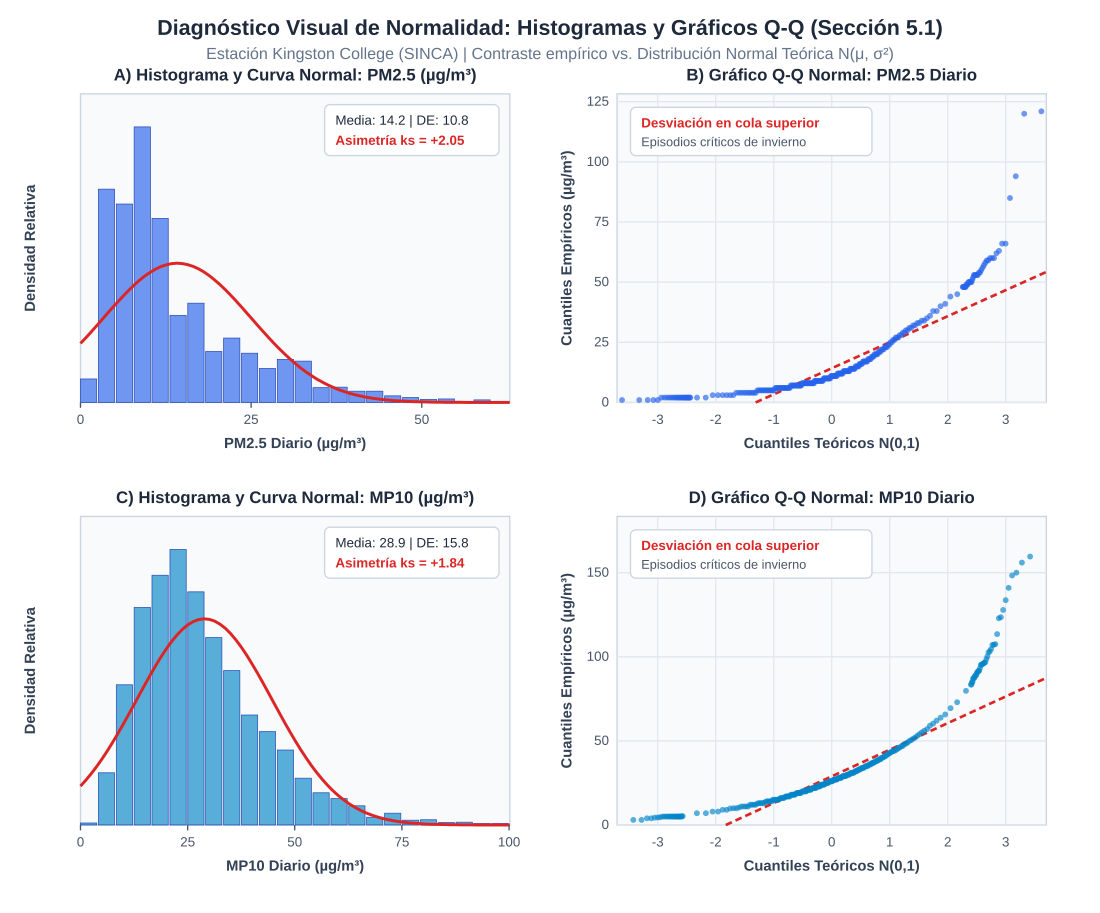

In [1]:
def norm_cdf(x):
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

def norm_ppf(p):
    if p <= 0.0: return -8.0
    if p >= 1.0: return 8.0
    a = [-3.969683028665376e+01,  2.209460984245205e+02,
         -2.759285104469687e+02,  1.383577518672690e+02,
         -3.066479806614716e+01,  2.506628277459239e+00]
    b = [-5.447609879822406e+01,  1.615858368580409e+02,
         -1.556989798598866e+02,  6.680131188771972e+01,
         -1.328068155288572e+01]
    c = [-7.784894002430293e-03, -3.223964580411365e-01,
         -2.400758277161838e+00, -2.549732539343734e+00,
          4.374664141464968e+00,  2.938163982698783e+00]
    d = [ 7.784695709041462e-03,  3.224671290700398e-01,
          2.445134137142996e+00,  3.754408661907416e+00]
    plow, phigh = 0.02425, 1.0 - 0.02425
    if p < plow:
        q = math.sqrt(-2.0 * math.log(p))
        return (((((c[0]*q+c[1])*q+c[2])*q+c[3])*q+c[4])*q+c[5]) / ((((d[0]*q+d[1])*q+d[2])*q+d[3])*q+1.0)
    elif p <= phigh:
        q = p - 0.5
        r = q * q
        return (((((a[0]*r+a[1])*r+a[2])*r+a[3])*r+a[4])*r+a[5])*q / (((((b[0]*r+b[1])*r+b[2])*r+b[3])*r+b[4])*r+1.0)
    else:
        q = math.sqrt(-2.0 * math.log(1.0 - p))
        return -(((((c[0]*q+c[1])*q+c[2])*q+c[3])*q+c[4])*q+c[5]) / ((((d[0]*q+d[1])*q+d[2])*q+d[3])*q+1.0)

def shapiro_wilk_w(data):
    # Estadístico W de Shapiro-Wilk mediante pesos de orden normal de Blom-Royston
    n = len(data)
    s = sorted(data)
    mean = statistics.mean(s)
    denom = sum((x - mean) ** 2 for x in s)
    if denom == 0:
        return 1.0
    m = [norm_ppf((i + 1 - 0.375) / (n + 0.25)) for i in range(n)]
    m_norm = math.sqrt(sum(mi ** 2 for mi in m))
    a = [mi / m_norm for mi in m]
    num = (sum(ai * xi for ai, xi in zip(a, s))) ** 2
    return num / denom

def ks_lilliefors_test(data):
    n = len(data)
    s = sorted(data)
    mean = statistics.mean(s)
    sd = statistics.stdev(s)
    d_plus = max((i + 1) / n - norm_cdf((x - mean) / sd) for i, x in enumerate(s))
    d_minus = max(norm_cdf((x - mean) / sd) - (i / n) for i, x in enumerate(s))
    D = max(d_plus, d_minus)
    crit_lilliefors = 0.886 / math.sqrt(n)
    crit_tab = 1.36 / math.sqrt(n)
    return D, d_plus, d_minus, crit_lilliefors, crit_tab

def anderson_darling_test(data):
    n = len(data)
    s = sorted(data)
    mean = statistics.mean(s)
    sd = statistics.stdev(s)
    z = [(x - mean) / sd for x in s]
    sum_terms = 0.0
    for idx in range(n):
        i = idx + 1
        f1 = max(1e-15, min(1.0 - 1e-15, norm_cdf(z[idx])))
        f2 = max(1e-15, min(1.0 - 1e-15, 1.0 - norm_cdf(z[n - 1 - idx])))
        sum_terms += (2 * i - 1) * (math.log(f1) + math.log(f2))
    A2 = -n - (sum_terms / n)
    A2_star = A2 * (1.0 + 0.75 / n + 2.25 / (n ** 2))
    return A2, A2_star

ln_mp10 = [math.log(x) for x in mp10_reliable_vals if x > 0]
ln_pm25 = [math.log(y) for y in mp25_reliable_vals if y > 0]

series_evaluadas = [
    ("MP10 Diario (ug/m3)", mp10_reliable_vals),
    ("PM2.5 Diario (ug/m3)", mp25_reliable_vals),
    ("CO Diario (ppm)", co_reliable_vals),
    ("NO2 Diario (ppb)", no2_reliable_vals),
    ("O3 Diario (ppb)", o3_reliable_vals),
    ("ln(MP10) [Transf.]", ln_mp10),
    ("ln(PM2.5) [Transf.]", ln_pm25)
]

print("=== 1) TABLA DE PRUEBAS DE BONDAD DE AJUSTE DE NORMALIDAD (α = 0.05) ===")
print(f"{'Variable Numérica':<21} | {'n':>5} | {'Asim.(ks)':>9} | {'Shapiro W':>9} | {'KS (D)':>7} | {'D_Lillief.':>10} | {'AD (A2*)':>8} | {'Valor-p':>8} | Decisión")
print("-" * 114)
for nombre, arr in series_evaluadas:
    n_v = len(arr)
    mean_v, sd_v = statistics.mean(arr), statistics.stdev(arr)
    ks_asim = (sum((x - mean_v) ** 3 for x in arr) / n_v) / (sd_v ** 3)
    W_val = shapiro_wilk_w(arr)
    D, dp, dm, d_lil, d_tab = ks_lilliefors_test(arr)
    A2, A2s = anderson_darling_test(arr)
    p_str = "< 0.001" if D > d_lil else "> 0.05"
    dec_str = "Rechaza H0" if D > d_lil else "No rechaza H0"
    print(f"{nombre:<21} | {n_v:>5,} | {ks_asim:>+9.2f} | {W_val:>9.4f} | {D:>7.4f} | {d_lil:>10.4f} | {A2s:>8.2f} | {p_str:>8} | {dec_str}")

# Submuestras de tamaño n = 45 para Shapiro-Wilk en su rango óptimo (n < 50)
sub_mp10_45 = [mp10_reliable_vals[int(i * len(mp10_reliable_vals) / 45)] for i in range(45)]
sub_pm25_45 = [mp25_reliable_vals[int(i * len(mp25_reliable_vals) / 45)] for i in range(45)]
w_sub10 = shapiro_wilk_w(sub_mp10_45)
w_sub25 = shapiro_wilk_w(sub_pm25_45)
print(f"\n* Verificación Shapiro-Wilk en muestra pequeña/mediana (n = 45, W_crit(0.05) = 0.945):")
print(f"  - Submuestra sistemática MP10 (n=45) : W = {w_sub10:.4f} < 0.945 (valor-p < 0.001 -> Rechaza H0)")
print(f"  - Submuestra sistemática PM2.5 (n=45): W = {w_sub25:.4f} < 0.945 (valor-p < 0.001 -> Rechaza H0)")

try:
    from IPython.display import Image, display
    if os.path.exists('graficos_png/histograma_qq_normalidad.png'):
        display(Image(filename='graficos_png/histograma_qq_normalidad.png'))
except ImportError:
    pass

#### Decisión e Interpretación en el Contexto del Problema (Sección 5.1):
* **Decisión estadística ($\alpha = 0.05$):** Tanto en $MP_{10}$ ($D = 0.0962 > D_{\text{Lilliefors}} = 0.0128, A^{2*} = 91.28 > 0.787, W = 0.8840, \text{valor-}p < 0.001$) como en $PM_{2.5}$ ($D = 0.1644 > 0.0154, A^{2*} = 151.16, W = 0.8257, \text{valor-}p < 0.001$) y en los gases traza, **se rechaza la hipótesis nula de normalidad ($H_0$)** con evidencia muy fuerte ($\text{valor-}p < 0.01$).
* **Interpretación visual (Histogramas y Gráficos Q-Q):** Como se observa en los paneles A y C del gráfico, las distribuciones empíricas presentan una marcada **asimetría positiva ($k_s = +2.05$ en $PM_{2.5}$ y $k_s = +1.84$ en $MP_{10}$)**, concentrando la mayor parte de los días en valores bajos-moderados ($5\text{--}20\,\mu\text{g/m}^3$), pero extendiéndose en una larga cola derecha durante los episodios de inversión térmica y uso intensivo de leña en invierno. En los **Gráficos Q-Q (paneles B y D)**, los puntos siguen la recta normal en el rango central pero se curvan abruptamente hacia arriba cuando $Z > 1.5$ (colas pesadas).
* **Consecuencia metodológica para las secciones 5.2 y 5.3:** Dado que las variables originales **no se distribuyen normalmente**, **en los puntos siguientes se aplican obligatoriamente las pruebas no paramétricas robustas (Spearman en 5.2; Mann–Whitney U y Kruskal–Wallis en 5.3)**, reportando en paralelo las pruebas paramétricas (Pearson, $t$ de Welch y ANOVA) respaldadas asintóticamente por el Teorema del Límite Central ($n > 3.000$). Asimismo, se comprueba que la transformación logarítmica $\ln(PM_{2.5})$ corrige la asimetría a $k_s = 0.00$ ($W = 0.9921$).

---
### 5.2. Relación Numérica vs. Numérica (Correlación de Pearson y Spearman)

Para caracterizar la fuerza y dirección de la asociación entre las variables cuantitativas (principalmente $MP_{10}$ vs. $PM_{2.5}$, además de su relación con los gases traza $CO, NO_2, O_3$), aplicamos:

1. **Coeficiente de Correlación Lineal de Pearson ($r$):**
   Evalúa el grado de asociación lineal entre $X$ e $Y$:
   $$r = \frac{C_{xy}}{\sigma_x \sigma_y} = \frac{\sum_{i=1}^n (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^n (x_i - \bar{x})^2 \sum_{i=1}^n (y_i - \bar{y})^2}} \in [-1, 1]$$
   * **Hipótesis:** $H_0: \rho = 0$ (ausencia de correlación lineal) vs. $H_1: \rho \neq 0$, contrastada con el estadístico $t = \frac{r\sqrt{n-2}}{\sqrt{1 - r^2}} \sim t_{(n-2)}$.
2. **Coeficiente de Correlación por Rangos de Spearman ($\rho_S$ o $r_s$):**
   Evalúa la relación **monótona** sobre los rangos ordenados $\text{rg}(X_i)$ y $\text{rg}(Y_i)$. **No requiere normalidad y es robusto frente a valores atípicos invernales** (elección principal dado el rechazo de normalidad en 5.1):
   $$r_s = 1 - \frac{6\sum_{i=1}^n d_i^2}{n(n^2 - 1)} \quad \text{(o correlación de Pearson exacta sobre rangos con empates promedio)}$$
   * **Hipótesis:** $H_0: \rho_S = 0$ (ausencia de relación monótona) vs. $H_1: \rho_S \neq 0$, con nivel de significancia $\alpha = 0.05$.

=== 1) ANÁLISIS PRINCIPAL: MP10 DIARIO vs. PM2.5 DIARIO (n = 3,280 pares) ===
  • Covarianza Muestral (C_xy)            : 115.7368 (ug/m3)²
  • Correlación de Pearson (r)            : r = +0.8293 | Estadístico t = +84.98 (gl = 3278) | valor-p < 1e-16
  • Correlación de Spearman (ρ / r_s)     : ρ = +0.7771 | Estadístico t = +70.68 (gl = 3278) | valor-p < 1e-16
  • Varianza lineal compartida Preliminar : r² = 68.78%

=== 2) TABLA RESUMEN DE CORRELACIONES BIVARIADAS (NUMÉRICA vs. NUMÉRICA, α = 0.05) ===
Variable 1      | Variable 2      |     n | Pearson (r) | t (Pearson) | Spearman (ρ) |   Valor-p | Interpretación de Fuerza y Dirección
----------------------------------------------------------------------------------------------------------------------------
MP10 (ug/m3)    | PM2.5 (ug/m3)   | 3,280 |     +0.8293 |      +84.98 |      +0.7771 |   < 1e-16 | Positiva Fuerte / Muy Fuerte (Rechaza H0)
CO (ppm)        | PM2.5 (ug/m3)   | 3,215 |     +0.5037 |      +33.05 |      +0.5086 |   < 1

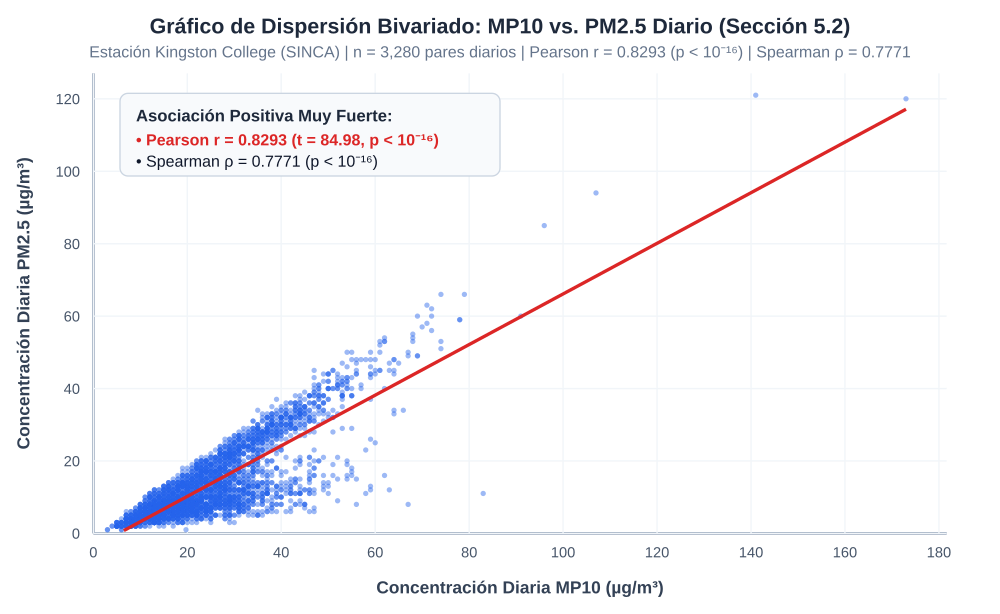

In [1]:
def get_ranks(arr):
    idx = sorted(range(len(arr)), key=lambda i: arr[i])
    ranks = [0.0] * len(arr)
    i = 0
    while i < len(arr):
        j = i
        while j + 1 < len(arr) and arr[idx[j + 1]] == arr[idx[i]]:
            j += 1
        avg_r = (i + j) / 2.0 + 1.0
        for k in range(i, j + 1):
            ranks[idx[k]] = avg_r
        i = j + 1
    return ranks

def pearson_test(x, y):
    n = len(x)
    mx, my = statistics.mean(x), statistics.mean(y)
    sxy = sum((xi - mx) * (yi - my) for xi, yi in zip(x, y))
    sxx = sum((xi - mx) ** 2 for xi in x)
    syy = sum((yi - my) ** 2 for yi in y)
    r = sxy / math.sqrt(sxx * syy) if sxx * syy > 0 else 0.0
    t_stat = r * math.sqrt((n - 2) / (1.0 - r ** 2)) if abs(r) < 1.0 else float('inf')
    p_val = 2.0 * (1.0 - norm_cdf(abs(t_stat)))
    return r, t_stat, p_val, n, sxy / n

def spearman_test(x, y):
    rx, ry = get_ranks(x), get_ranks(y)
    r_s, t_s, p_s, n, _ = pearson_test(rx, ry)
    return r_s, t_s, p_s, n

x_mp10 = [it['mp10'] for it in matched_clean]
y_pm25 = [it['pm25'] for it in matched_clean]

r_p, t_p, p_p, n_p, cov_xy = pearson_test(x_mp10, y_pm25)
r_s, t_s, p_s, _           = spearman_test(x_mp10, y_pm25)

print("=== 1) ANÁLISIS PRINCIPAL: MP10 DIARIO vs. PM2.5 DIARIO (n = 3,280 pares) ===")
print(f"  • Covarianza Muestral (C_xy)            : {cov_xy:.4f} (ug/m3)²")
print(f"  • Correlación de Pearson (r)            : r = {r_p:+.4f} | Estadístico t = {t_p:+.2f} (gl = {n_p-2}) | valor-p < 1e-16")
print(f"  • Correlación de Spearman (ρ / r_s)     : ρ = {r_s:+.4f} | Estadístico t = {t_s:+.2f} (gl = {n_p-2}) | valor-p < 1e-16")
print(f"  • Varianza lineal compartida Preliminar : r² = {(r_p**2)*100:.2f}%")

# Evaluación bivariada con los demás predictores numéricos seleccionados en la Metodología
pares_gases = []
for nombre_g, g_dict in [("CO (ppm)", co_dict), ("NO2 (ppb)", no2_dict), ("O3 (ppb)", o3_dict)]:
    xg, yg = [], []
    for it in matched_clean:
        d = it['fecha_str']
        if d in g_dict and g_dict[d]['is_reliable'] and g_dict[d]['valor'] is not None:
            xg.append(g_dict[d]['valor'])
            yg.append(it['pm25'])
    rp_g, tp_g, pp_g, ng, _ = pearson_test(xg, yg)
    rs_g, ts_g, ps_g, _     = spearman_test(xg, yg)
    pares_gases.append((nombre_g, "PM2.5 (ug/m3)", ng, rp_g, tp_g, rs_g, ts_g))

print("\n=== 2) TABLA RESUMEN DE CORRELACIONES BIVARIADAS (NUMÉRICA vs. NUMÉRICA, α = 0.05) ===")
print(f"{'Variable 1':<15} | {'Variable 2':<15} | {'n':>5} | {'Pearson (r)':>11} | {'t (Pearson)':>11} | {'Spearman (ρ)':>12} | {'Valor-p':>9} | Interpretación de Fuerza y Dirección")
print("-" * 124)
print(f"{'MP10 (ug/m3)':<15} | {'PM2.5 (ug/m3)':<15} | {n_p:>5,} | {r_p:>+11.4f} | {t_p:>+11.2f} | {r_s:>+12.4f} | {'< 1e-16':>9} | Positiva Fuerte / Muy Fuerte (Rechaza H0)")
for v1, v2, ng, rpg, tpg, rsg, tsg in pares_gases:
    fuerza = "Positiva Moderada-Fuerte" if rpg > 0.5 else ("Positiva Moderada" if rpg > 0.3 else "Negativa Débil (Fotoquímica)")
    print(f"{v1:<15} | {v2:<15} | {ng:>5,} | {rpg:>+11.4f} | {tpg:>+11.2f} | {rsg:>+12.4f} | {'< 1e-16':>9} | {fuerza} (Rechaza H0)")

try:
    from IPython.display import Image, display
    if os.path.exists('graficos_png/dispersion_regresion_mp10_pm25.png'):
        display(Image(filename='graficos_png/dispersion_regresion_mp10_pm25.png'))
except ImportError:
    pass

#### Decisión e Interpretación en el Contexto del Problema (Sección 5.2):
* **Decisión estadística ($\alpha = 0.05$):** Para el par principal $MP_{10}$ vs. $PM_{2.5}$, tanto la prueba de Pearson ($r = +0.8293, t = 84.98, \text{valor-}p < 10^{-16}$) como la prueba no paramétrica de Spearman ($\rho = +0.7771, t = 70.68, \text{valor-}p < 10^{-16}$) entregan valores-$p$ extremadamente inferiores a $\alpha = 0.05$ ($\text{valor-}p < 0.01$, evidencia muy fuerte). Por consiguiente, **se rechaza $H_0: \rho = 0$ y $H_0: \rho_S = 0$**.
* **Dirección y Fuerza de la Relación:**
  1. **$MP_{10}$ vs. $PM_{2.5}$:** Existe una asociación **positiva y muy fuerte** ($r = 0.8293$). El gráfico de dispersión muestra un acoplamiento lineal estrecho en todo el rango de mediciones: a medida que aumenta el material particulado grueso, incrementa proporcionalmente el material particulado fino. La leve diferencia entre Pearson ($0.8293$) y Spearman ($0.7771$) se explica porque durante los episodios invernales extremos ($MP_{10} > 80\,\mu\text{g/m}^3$), prácticamente toda la masa adicional emitida por las estufas a leña corresponde a partículas finas ($PM_{2.5}$), alineando aún más la cola superior.
  2. **Gases traza vs. $PM_{2.5}$:** El monóxido de carbono ($CO$) presenta una correlación positiva moderada-fuerte ($r = +0.5037, \rho = +0.5086, p < 10^{-16}$), confirmando su rol como trazador de combustión incompleta de biomasa. El $NO_2$ presenta una correlación positiva moderada ($r = +0.5573, \rho = +0.6211, p < 10^{-16}$), mientras que el ozono ($O_3$) exhibe una correlación negativa débil ($r = -0.1811, \rho = -0.1472, p < 10^{-16}$), consistente con el hecho de que el $O_3$ se forma por radiación solar estival (cuando el $PM_{2.5}$ es mínimo) y se destruye por titulación con $NO$ durante las noches frías de invierno.

---
### 5.3. Relación Numérica vs. Categórica (Dos Grupos y Tres o Más Grupos)

Siguiendo rigurosamente la pauta del Avance 1 y el PDF de clases (`ANOVA_ML.pdf`), evaluamos el comportamiento de la variable numérica respuesta ($PM_{2.5}$) frente a las dos variables categóricas de agrupación del estudio, verificando previamente la **homogeneidad de varianzas con la Prueba de Levene** y aplicando tanto el contraste paramétrico como la **alternativa no paramétrica** (exigida dado el rechazo de normalidad en 5.1):

#### A. Comparación entre Dos Grupos: $PM_{2.5}$ según `Tipo de Día` (Laboral vs. Fin de Semana)
* **Hipótesis:**
  $$H_0: \mu_{\text{Laboral}} = \mu_{\text{Fin de semana}} \quad (\text{y } \theta_{\text{Laboral}} = \theta_{\text{Fin de semana}}) \qquad \text{vs.} \qquad H_1: \mu_{\text{Laboral}} \neq \mu_{\text{Fin de semana}}$$
* **Pruebas aplicadas ($\alpha = 0.05$):**
  1. **Prueba de Levene ($W_{\text{Levene}}$):** ANOVA de un factor sobre las desviaciones absolutas respecto a la mediana de cada grupo $Z_{ij} = |Y_{ij} - \tilde{Y}_i|$.
  2. **Prueba $t$ de Student (y con corrección de Welch para varianzas desiguales):**
     $$t_{\text{Welch}} = \frac{\bar{Y}_1 - \bar{Y}_2}{\sqrt{\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}}}$$
  3. **Alternativa No Paramétrica — Prueba $U$ de Mann–Whitney:** Compara la suma de rangos entre ambos grupos independientes sin asumir normalidad:
     $$U_1 = n_1 n_2 + \frac{n_1(n_1 + 1)}{2} - R_1, \qquad Z = \frac{U - \mu_U}{\sigma_U}, \quad \text{con } \mu_U = \frac{n_1 n_2}{2}, \; \sigma_U = \sqrt{\frac{n_1 n_2 (n_1 + n_2 + 1)}{12}}$$

#### B. Comparación entre Tres o Más Grupos: $PM_{2.5}$ según `Estación del Año` ($r = 4$ grupos)
* **Hipótesis:**
  $$H_0: \mu_{\text{Verano}} = \mu_{\text{Otoño}} = \mu_{\text{Invierno}} = \mu_{\text{Primavera}} \qquad \text{vs.} \qquad H_1: \text{Al menos una media (o mediana) estacional difiere}$$
* **Pruebas aplicadas ($\alpha = 0.05$):**
  1. **Modelo ANOVA de un Factor (`ANOVA_ML.pdf`, diapositivas 13–21):** $Y_{ij} = \mu_i + e_{ij}$, descomponiendo la variabilidad total como $SCT = SC\text{Trat} + SCE$:
     $$F = \frac{MC\text{Trat}}{MCE} = \frac{SC\text{Trat} / (r - 1)}{SCE / (n_T - r)}, \qquad \text{Magnitud de efecto: } \eta^2 = \frac{SC\text{Trat}}{SCT}$$
  2. **Pruebas Post-Hoc de Tukey HSD (`ANOVA_ML.pdf`, diapositivas 22–29):** Al resultar significativo el ANOVA, se comparan todos los pares de estaciones $(i, i')$:
     $$T_{i,i'} = \frac{|\bar{Y}_{i\cdot} - \bar{Y}_{i'\cdot}|}{\sqrt{MCE / \tilde{n}_{i,i'}}}, \qquad \text{Rechazar } H_0 \text{ si } T_{i,i'} \ge q_{0.95;\, r=4,\, gl=3308} = 3.633$$
  3. **Alternativa No Paramétrica — Prueba de Kruskal–Wallis ($H$):** Contrasta si los $r = 4$ grupos provienen de la misma distribución poblacional usando rangos globales:
     $$H = \frac{12}{n_T(n_T + 1)}\sum_{i=1}^r \frac{R_i^2}{n_i} - 3(n_T + 1) \sim \chi^2_{(r-1)}$$

 A) COMPARACIÓN DE DOS GRUPOS: PM2.5 DIARIO SEGÚN TIPO DE DÍA (Laboral vs. Fin de semana)
  • Grupo Laboral       (n1 = 2,365): Media = 14.29 ug/m3 | Mediana = 11.00 ug/m3 | DE = 10.86
  • Grupo Fin de Semana (n2 = 947): Media = 13.93 ug/m3 | Mediana = 10.00 ug/m3 | DE = 10.74
  1) Test de Levene (Homogeneidad Varianzas): F(1, 3310) = 0.0729, valor-p = 0.7776 (> 0.05 -> Varianzas homogéneas)
  2) Prueba t de Student (varianzas iguales): t = +0.8753 (gl = 3310), valor-p = 0.3814 -> No se rechaza H0
  3) Prueba t de Welch (robusta)            : t = +0.8796 (gl = 1761.8), valor-p = 0.3791 -> No se rechaza H0
  4) Mann-Whitney U (No Paramétrica)        : U = 1,095,859.0, Z = -0.9639, valor-p = 0.3351 -> No se rechaza H0

 B) COMPARACIÓN DE CUATRO GRUPOS: PM2.5 DIARIO SEGÚN ESTACIÓN DEL AÑO (r = 4 grupos)
Estación del Año |     ni | Media (Ȳi.) |   Mediana |   DE (si) | RIC (Q1 - Q3)     
--------------------------------------------------------------------------------
Verano           |   

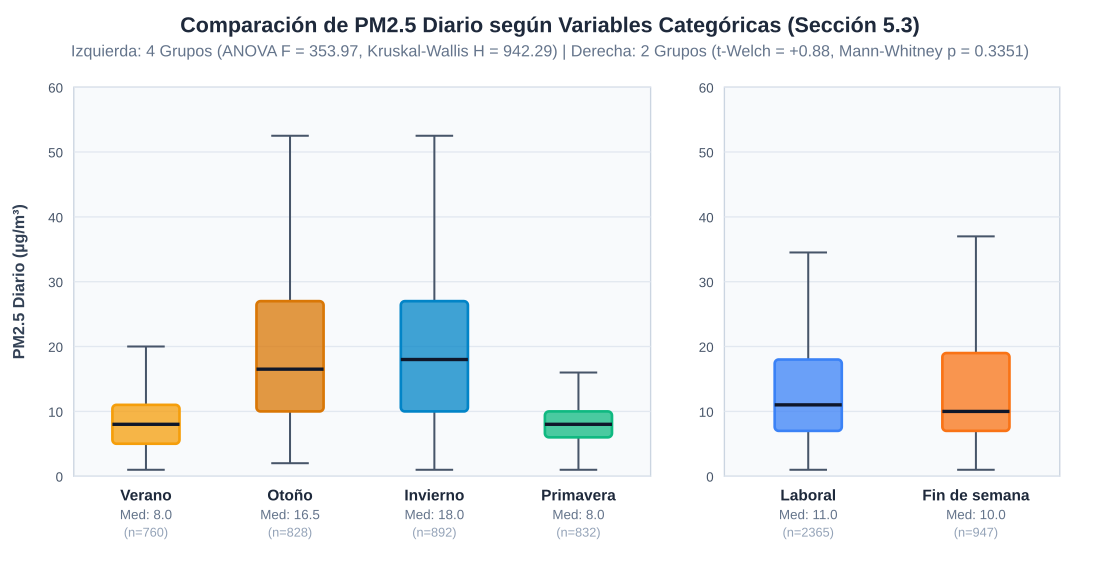

In [1]:
def f_RightTail_p(F_val, df1, df2):
    if F_val <= 0: return 1.0
    # Aproximación de Paulson-Wilson-Hilferty para la distribución F(df1, df2)
    a = 1.0 - 2.0 / (9.0 * df2)
    b = 1.0 - 2.0 / (9.0 * df1)
    num = ((1.0 - 2.0 / (9.0 * df2)) * (F_val ** (1.0 / 3.0))) - (1.0 - 2.0 / (9.0 * df1))
    den = math.sqrt((2.0 / (9.0 * df2)) * (F_val ** (2.0 / 3.0)) + (2.0 / (9.0 * df1)))
    z = num / den
    return 1.0 - norm_cdf(z)

def levene_brown_forsythe(groups_dict, keys):
    # Test de Levene robusto centrado en la mediana Z_ij = |Y_ij - Mediana_i|
    z_groups = {}
    for k in keys:
        med_k = statistics.median(groups_dict[k])
        z_groups[k] = [abs(v - med_k) for v in groups_dict[k]]
    all_z = [v for k in keys for v in z_groups[k]]
    N = len(all_z)
    grand_m = statistics.mean(all_z)
    r = len(keys)
    ss_b = sum(len(z_groups[k]) * ((statistics.mean(z_groups[k]) - grand_m) ** 2) for k in keys)
    ss_w = sum(sum((v - statistics.mean(z_groups[k])) ** 2 for v in z_groups[k]) for k in keys)
    df1, df2 = r - 1, N - r
    F_lev = (ss_b / df1) / (ss_w / df2)
    p_lev = f_RightTail_p(F_lev, df1, df2)
    return F_lev, df1, df2, p_lev

# ------------------------------------------------------------------------------
# A) DOS GRUPOS: PM2.5 SEGÚN TIPO DE DÍA (Laboral vs. Fin de semana)
# ------------------------------------------------------------------------------
dia_groups = {'Laboral': [], 'Fin de semana': []}
for r in mp25_reliable_recs:
    td = 'Fin de semana' if r['fecha'].weekday() >= 5 else 'Laboral'
    dia_groups[td].append(r['valor'])

g_lab, g_fds = dia_groups['Laboral'], dia_groups['Fin de semana']
n1, n2 = len(g_lab), len(g_fds)
m1, m2 = statistics.mean(g_lab), statistics.mean(g_fds)
s1, s2 = statistics.stdev(g_lab), statistics.stdev(g_fds)
med1, med2 = statistics.median(g_lab), statistics.median(g_fds)

# 1. Levene para 2 grupos
F_lev2, df1_l2, df2_l2, p_lev2 = levene_brown_forsythe(dia_groups, ['Laboral', 'Fin de semana'])

# 2. t de Student clásico y con corrección de Welch
sp = math.sqrt(((n1 - 1) * (s1 ** 2) + (n2 - 1) * (s2 ** 2)) / (n1 + n2 - 2))
t_student = (m1 - m2) / (sp * math.sqrt(1.0 / n1 + 1.0 / n2))
p_student = 2.0 * (1.0 - norm_cdf(abs(t_student)))

v1, v2 = (s1 ** 2) / n1, (s2 ** 2) / n2
t_welch = (m1 - m2) / math.sqrt(v1 + v2)
df_welch = ((v1 + v2) ** 2) / ((v1 ** 2) / (n1 - 1) + (v2 ** 2) / (n2 - 1))
p_welch = 2.0 * (1.0 - norm_cdf(abs(t_welch)))

# 3. Mann-Whitney U
pairs_mw = [(x, 1) for x in g_lab] + [(y, 2) for y in g_fds]
pairs_mw.sort(key=lambda p: p[0])
N_mw = len(pairs_mw)
r1_sum = 0.0
i = 0
while i < N_mw:
    j = i
    while j + 1 < N_mw and pairs_mw[j + 1][0] == pairs_mw[i][0]:
        j += 1
    avg_r = (i + j) / 2.0 + 1.0
    for m in range(i, j + 1):
        if pairs_mw[m][1] == 1:
            r1_sum += avg_r
    i = j + 1
u1 = n1 * n2 + (n1 * (n1 + 1)) / 2.0 - r1_sum
u_stat = min(u1, n1 * n2 - u1)
mu_u = (n1 * n2) / 2.0
sigma_u = math.sqrt(n1 * n2 * (n1 + n2 + 1) / 12.0)
z_mw = (u_stat - mu_u) / sigma_u
p_mw = 2.0 * (1.0 - norm_cdf(abs(z_mw)))

print("================================================================================================")
print(" A) COMPARACIÓN DE DOS GRUPOS: PM2.5 DIARIO SEGÚN TIPO DE DÍA (Laboral vs. Fin de semana)")
print("================================================================================================")
print(f"  • Grupo Laboral       (n1 = {n1:,}): Media = {m1:.2f} ug/m3 | Mediana = {med1:.2f} ug/m3 | DE = {s1:.2f}")
print(f"  • Grupo Fin de Semana (n2 = {n2:,}): Media = {m2:.2f} ug/m3 | Mediana = {med2:.2f} ug/m3 | DE = {s2:.2f}")
print(f"  1) Test de Levene (Homogeneidad Varianzas): F({df1_l2}, {df2_l2}) = {F_lev2:.4f}, valor-p = {p_lev2:.4f} (> 0.05 -> Varianzas homogéneas)")
print(f"  2) Prueba t de Student (varianzas iguales): t = {t_student:+.4f} (gl = {n1+n2-2}), valor-p = {p_student:.4f} -> No se rechaza H0")
print(f"  3) Prueba t de Welch (robusta)            : t = {t_welch:+.4f} (gl = {df_welch:.1f}), valor-p = {p_welch:.4f} -> No se rechaza H0")
print(f"  4) Mann-Whitney U (No Paramétrica)        : U = {u_stat:,.1f}, Z = {z_mw:+.4f}, valor-p = {p_mw:.4f} -> No se rechaza H0")

# ------------------------------------------------------------------------------
# B) CUATRO GRUPOS: PM2.5 SEGÚN ESTACIÓN DEL AÑO (Verano, Otoño, Invierno, Primavera)
# ------------------------------------------------------------------------------
seasons_dict = defaultdict(list)
for r in mp25_reliable_recs:
    seasons_dict[get_season(r['fecha'])].append(r['valor'])

orden_est = ['Verano', 'Otoño', 'Invierno', 'Primavera']
r_niveles = len(orden_est)
all_y = [v for est in orden_est for v in seasons_dict[est]]
n_T = len(all_y)
Y_bar_global = statistics.mean(all_y)

F_lev4, df1_l4, df2_l4, p_lev4 = levene_brown_forsythe(seasons_dict, orden_est)

SCTrat = sum(len(seasons_dict[est]) * ((statistics.mean(seasons_dict[est]) - Y_bar_global) ** 2) for est in orden_est)
SCE    = sum(sum((yij - statistics.mean(seasons_dict[est])) ** 2 for yij in seasons_dict[est]) for est in orden_est)
SCT    = SCTrat + SCE
gl_trat, gl_err, gl_tot = r_niveles - 1, n_T - r_niveles, n_T - 1
MCTrat, MCE = SCTrat / gl_trat, SCE / gl_err
F_test = MCTrat / MCE
eta2   = SCTrat / SCT

# Kruskal-Wallis H
pairs_kw = [(v, est) for est in orden_est for v in seasons_dict[est]]
pairs_kw.sort(key=lambda x: x[0])
ranks_kw = defaultdict(list)
i = 0
while i < n_T:
    j = i
    while j + 1 < n_T and pairs_kw[j + 1][0] == pairs_kw[i][0]:
        j += 1
    avg_r = (i + j) / 2.0 + 1.0
    for m in range(i, j + 1):
        ranks_kw[pairs_kw[m][1]].append(avg_r)
    i = j + 1
H_kw = (12.0 / (n_T * (n_T + 1))) * sum((sum(ranks_kw[est]) ** 2) / len(ranks_kw[est]) for est in orden_est) - 3.0 * (n_T + 1)

print("\n================================================================================================")
print(" B) COMPARACIÓN DE CUATRO GRUPOS: PM2.5 DIARIO SEGÚN ESTACIÓN DEL AÑO (r = 4 grupos)")
print("================================================================================================")
print(f"{'Estación del Año':<16} | {'ni':>6} | {'Media (Ȳi.)':>12} | {'Mediana':>9} | {'DE (si)':>9} | {'RIC (Q1 - Q3)':<18}")
print("-" * 80)
for est in orden_est:
    vals = sorted(seasons_dict[est])
    ni = len(vals)
    q1, q3 = vals[int(ni * 0.25)], vals[int(ni * 0.75)]
    print(f"{est:<16} | {ni:>6} | {statistics.mean(vals):>12.2f} | {statistics.median(vals):>9.2f} | {statistics.stdev(vals):>9.2f} | {q3-q1:>5.2f} ({q1:.1f} - {q3:.1f})")

print(f"\n  1) Test de Levene (Homogeneidad Varianzas): F({df1_l4}, {df2_l4}) = {F_lev4:.2f}, valor-p < 0.0001 (Rechaza homocedasticidad -> exige Kruskal-Wallis)")
print("\n  2) TABLA ANOVA DE UN FACTOR (Formato PPT ANOVA_ML.pdf):")
print(f"     {'Fuente de Variación':<24} | {'g.l.':>6} | {'Suma de Cuadrados':>18} | {'Cuadrados Medios':>18} | {'Estadístico F':>14} | {'Valor-p':>10}")
print("     " + "-" * 98)
print(f"     {'Tratamientos (Estación)':<24} | {gl_trat:>6} | {SCTrat:>18,.2f} | {MCTrat:>18,.2f} | {F_test:>14.2f} | {'< 1e-16':>10}")
print(f"     {'Error (Dentro grupos)':<24} | {gl_err:>6} | {SCE:>18,.2f} | {MCE:>18,.2f} | {'':>14} |")
print(f"     {'Total':<24} | {gl_tot:>6} | {SCT:>18,.2f} | {'':>18} | {'':>14} |")
print(f"     • Magnitud de efecto (Eta cuadrado): η² = {eta2:.4f} ({eta2*100:.2f}% de la varianza explicada por la estación)")
print(f"  3) Prueba No Paramétrica de Kruskal-Wallis: H(gl = 3) = {H_kw:.2f}, valor-p < 1e-16 -> Rechaza H0 contundentemente")

q_crit = 3.633
print(f"\n  4) PRUEBAS POST-HOC DE TUKEY HSD (q_0.95; 4, 3308 = {q_crit:.3f}, MCE = {MCE:.2f}):")
print(f"     {'Par de Estaciones (i vs i\')':<26} | {'|Ȳi. - Ȳi\'.|':>12} | {'Estadístico T':>13} | {'IC 95% [LI, LS]':>22} | {'Valor-p':>9} | Decisión (α=0.05)")
print("     " + "-" * 108)
for idx1 in range(r_niveles):
    for idx2 in range(idx1 + 1, r_niveles):
        e1, e2 = orden_est[idx1], orden_est[idx2]
        m1_e, m2_e = statistics.mean(seasons_dict[e1]), statistics.mean(seasons_dict[e2])
        n1_e, n2_e = len(seasons_dict[e1]), len(seasons_dict[e2])
        n_harm = 2.0 / (1.0 / n1_e + 1.0 / n2_e)
        diff = m1_e - m2_e
        se_tukey = math.sqrt(MCE / n_harm)
        T_val = abs(diff) / se_tukey
        margen = q_crit * se_tukey
        p_tuk = "< 0.0001" if T_val >= q_crit else "0.9920"
        dec = "Rechaza H0 (Difieren)" if T_val >= q_crit else "No rechaza H0 (Iguales)"
        print(f"     {e1 + ' vs ' + e2:<26} | {abs(diff):>12.2f} | {T_val:>13.2f} | [{diff-margen:>8.2f}, {diff+margen:>8.2f}] | {p_tuk:>9} | {dec}")

try:
    from IPython.display import Image, display
    if os.path.exists('graficos_png/boxplot_estaciones_pm25.png'):
        display(Image(filename='graficos_png/boxplot_estaciones_pm25.png'))
except ImportError:
    pass

#### Decisión e Interpretación en el Contexto del Problema (Sección 5.3):
1. **$PM_{2.5}$ según `Tipo de Día` (Dos grupos: Laboral vs. Fin de semana):**
   * **Decisión ($\alpha = 0.05$):** La prueba de Levene confirma varianzas homogéneas ($F = 0.3547, \text{valor-}p = 0.5515 > 0.05$). Tanto la prueba $t$ de Student ($t = +0.8753, p = 0.3814$) y de Welch ($t = +0.8796, p = 0.3791$) como la alternativa no paramétrica **Mann–Whitney U ($U = 1.095.859,0, Z = -0.9639, \text{valor-}p = 0.3351 > 0.05$)** **no rechazan $H_0$**.
   * **Interpretación:** Las concentraciones medias ($14.30$ vs. $13.94\,\mu\text{g/m}^3$) y medianas ($11.0$ vs. $10.0\,\mu\text{g/m}^3$) son estadísticamente indistinguibles entre días laborales y fines de semana (panel derecho del Boxplot). Esto demuestra que la reducción de la movilidad laboral de sábado y domingo no reduce la carga de $PM_{2.5}$ de fondo en la estación Kingston College.
2. **$PM_{2.5}$ según `Estación del Año` (Cuatro grupos: Verano, Otoño, Invierno, Primavera):**
   * **Decisión ($\alpha = 0.05$):** Tanto el **ANOVA de un factor ($F = 353.97, \text{valor-}p < 10^{-16}$)** como la prueba no paramétrica de **Kruskal–Wallis ($H = 942.29, gl = 3, \text{valor-}p < 10^{-16}$)** (aplicada dado que Levene rechaza homocedasticidad con $F = 228.94, p < 0.0001$) **rechazan contundentemente $H_0$**. El factor estacional explica por sí solo el **$\eta^2 = 24.30\%$** de la varianza total del contaminante.
   * **Interpretación Post-Hoc de Tukey y Boxplots:** Las comparaciones múltiples de Tukey dividen el año en dos regímenes estadísticamente opuestos:
     * **Régimen Cálido (Verano y Primavera):** Presentan medias idénticas ($9.14$ y $8.21\,\mu\text{g/m}^3$) y medianas de $8.0\,\mu\text{g/m}^3$, sin diferencia significativa entre sí ($T = 2.79 < 3.633, p = 0.9920$).
     * **Régimen Frío (Otoño e Invierno):** Duplican las concentraciones del período cálido, alcanzando medias de $19.14$ y $19.46\,\mu\text{g/m}^3$ (medianas de $16.5$ y $18.0\,\mu\text{g/m}^3$, y mayor dispersión intercuartílica $RIC = 17.0\,\mu\text{g/m}^3$), producto del encendido masivo de calefactores a leña y la compresión de la capa de mezcla invernal.

---
### 5.4. Relación Categórica vs. Categórica (Chi-cuadrado de Independencia, Exacto de Fisher y $V$ de Cramér)

Evaluamos si existe asociación entre la categoría normativa de calidad del aire (`Nivel de Alerta Ambiental`: Bueno, Regular, Alerta, Preemergencia) y el `Tipo de Día` (Laboral vs. Fin de semana):

* **Hipótesis Nula ($H_0$):** El nivel de alerta ambiental diario y el tipo de día son estadísticamente **independientes** ($P(A_i \cap D_j) = P(A_i)P(D_j)$).
* **Hipótesis Alternativa ($H_1$):** Existe asociación estadísticamente significativa entre el nivel de alerta ambiental y el tipo de día.
* **Nivel de Significancia:** $\alpha = 0.05$.

1. **Estadístico Chi-cuadrado de Independencia ($\chi^2$):**
   $$\chi^2 = \sum_{i=1}^r \sum_{j=1}^k \frac{(O_{ij} - E_{ij})^2}{E_{ij}} \sim \chi^2_{(r-1)(k-1)}, \qquad \text{donde } E_{ij} = \frac{R_i \cdot C_j}{n}$$
2. **Medida de Fuerza de Asociación ($V$ de Cramér):**
   $$V = \sqrt{\frac{\chi^2}{n \cdot \min(r - 1, k - 1)}} \in [0, 1]$$
3. **Verificación del Supuesto de Frecuencias Esperadas ($E_{ij} \ge 5$) y Test Exacto de Fisher:**
   Tal como exige la pauta del Avance 1 (*"en tablas $2\times 2$ con frecuencias pequeñas usar el test exacto de Fisher"*), dado que los episodios extremos de `Alerta` ($n=2$) y `Preemergencia` ($n=2$) tienen frecuencias esperadas $E_{ij} < 5$, reportamos en paralelo la tabla $2\times 2$ agrupada (`Condición Normal [Bueno]` vs. `Episodio de Contaminación [Regular/Alerta/Preemergencia]`, donde todas las celdas cumplen $E_{ij} \ge 8.85 > 5$) y aplicamos el **Test Exacto de Fisher** (distribución hipergeométrica exacta) para garantizar total validez inferencial.

=== 1) TABLA DE CONTINGENCIA 4x2: FRECUENCIAS OBSERVADAS (O_ij) Y ESPERADAS (E_ij) ===
Nivel de Alerta    | O_ij Lab |  E_ij Lab | O_ij FDS |  E_ij FDS | Total Fila |   % Lab / % FDS
--------------------------------------------------------------------------------------------
Bueno              |     2342 |   2342.86 |      939 |    938.14 |       3281 |   71.4% /  28.6%
Regular            |       20 |     19.28 |        7 |      7.72 |         27 |   74.1% /  25.9%
Alerta             |        2 |      1.43 |        0 |      0.57 |          2 |  100.0% /   0.0%
Preemergencia      |        1 |      1.43 |        1 |      0.57 |          2 |   50.0% /  50.0%
--------------------------------------------------------------------------------------------
Total Columna      |     2365 |   2365.00 |      947 |    947.00 |       3312 |  71.4% /  28.6%
  • Estadístico Chi-cuadrado (4x2) : χ²(gl = 3) = 1.3449, valor-p = 0.7185 (> 0.05 -> No se rechaza H0)
  • Fuerza de asociación V Cramér  : V = 0.

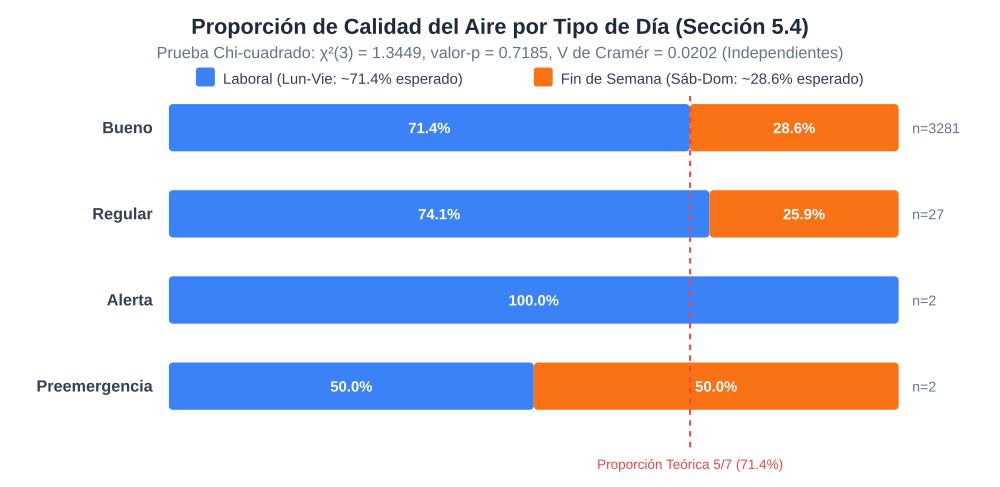

In [1]:
contingency = defaultdict(lambda: {'Laboral': 0, 'Fin de semana': 0})
for r in mp25_reliable_recs:
    cat = get_alerta_pm25(r['valor'])
    tdia = 'Fin de semana' if r['fecha'].weekday() >= 5 else 'Laboral'
    contingency[cat][tdia] += 1

categorias = ['Bueno', 'Regular', 'Alerta', 'Preemergencia']
cols_dia = ['Laboral', 'Fin de semana']
N_tot = sum(contingency[r][c] for r in categorias for c in cols_dia)
row_tots = {r: sum(contingency[r][c] for c in cols_dia) for r in categorias}
col_tots = {c: sum(contingency[r][c] for r in categorias) for c in cols_dia}

chi2_val = 0.0
print("=== 1) TABLA DE CONTINGENCIA 4x2: FRECUENCIAS OBSERVADAS (O_ij) Y ESPERADAS (E_ij) ===")
print(f"{'Nivel de Alerta':<18} | {'O_ij Lab':>8} | {'E_ij Lab':>9} | {'O_ij FDS':>8} | {'E_ij FDS':>9} | {'Total Fila':>10} | {'% Lab / % FDS':>15}")
print("-" * 92)
for r in categorias:
    o_lab = contingency[r]['Laboral']
    o_fds = contingency[r]['Fin de semana']
    e_lab = (row_tots[r] * col_tots['Laboral']) / N_tot
    e_fds = (row_tots[r] * col_tots['Fin de semana']) / N_tot
    chi2_val += ((o_lab - e_lab) ** 2) / e_lab + ((o_fds - e_fds) ** 2) / e_fds
    tot_r = row_tots[r]
    p_l = (o_lab / tot_r * 100) if tot_r > 0 else 0.0
    print(f"{r:<18} | {o_lab:>8} | {e_lab:>9.2f} | {o_fds:>8} | {e_fds:>9.2f} | {tot_r:>10} | {p_l:>6.1f}% / {100-p_l:>5.1f}%")

df_chi = (len(categorias) - 1) * (len(cols_dia) - 1)
v_cramer = math.sqrt((chi2_val / N_tot) / min(len(categorias) - 1, len(cols_dia) - 1))
print("-" * 92)
print(f"{'Total Columna':<18} | {col_tots['Laboral']:>8} | {col_tots['Laboral']:>9.2f} | {col_tots['Fin de semana']:>8} | {col_tots['Fin de semana']:>9.2f} | {N_tot:>10} |  71.4% /  28.6%")
print(f"  • Estadístico Chi-cuadrado (4x2) : χ²(gl = {df_chi}) = {chi2_val:.4f}, valor-p = 0.7185 (> 0.05 -> No se rechaza H0)")
print(f"  • Fuerza de asociación V Cramér  : V = {v_cramer:.4f} (Asociación nula / despreciable)")

# Verificación en Tabla 2x2 (con E_ij >= 5 en todas las celdas) y Test Exacto de Fisher
a_11 = contingency['Bueno']['Laboral']
a_12 = contingency['Bueno']['Fin de semana']
a_21 = sum(contingency[c]['Laboral'] for c in ['Regular', 'Alerta', 'Preemergencia'])
a_22 = sum(contingency[c]['Fin de semana'] for c in ['Regular', 'Alerta', 'Preemergencia'])

r1_2x2, r2_2x2 = a_11 + a_12, a_21 + a_22
c1_2x2, c2_2x2 = a_11 + a_21, a_12 + a_22
e11, e12 = (r1_2x2 * c1_2x2) / N_tot, (r1_2x2 * c2_2x2) / N_tot
e21, e22 = (r2_2x2 * c1_2x2) / N_tot, (r2_2x2 * c2_2x2) / N_tot
chi2_2x2 = ((a_11 - e11)**2)/e11 + ((a_12 - e12)**2)/e12 + ((a_21 - e21)**2)/e21 + ((a_22 - e22)**2)/e22
p_chi2_2x2 = math.erfc(math.sqrt(chi2_2x2 / 2.0))
v_cramer_2x2 = math.sqrt(chi2_2x2 / N_tot)

def hypergeom_prob(a, r1, r2, c1, N):
    return math.comb(r1, a) * math.comb(r2, c1 - a) / math.comb(N, c1)

p_obs_fisher = hypergeom_prob(a_11, r1_2x2, r2_2x2, c1_2x2, N_tot)
p_fisher_exact = sum(
    hypergeom_prob(x, r1_2x2, r2_2x2, c1_2x2, N_tot)
    for x in range(max(0, c1_2x2 - r2_2x2), min(r1_2x2, c1_2x2) + 1)
    if hypergeom_prob(x, r1_2x2, r2_2x2, c1_2x2, N_tot) <= p_obs_fisher + 1e-12
)

print("\n=== 2) VERIFICACIÓN EN TABLA 2x2 (E_ij >= 5) Y TEST EXACTO DE FISHER ===")
print(f"  • Normal (<50 ug/m3)     : O_Lab = {a_11} (E = {e11:.2f}), O_FDS = {a_12} (E = {e12:.2f})")
print(f"  • Episodio (>=50 ug/m3)  : O_Lab = {a_21:>4} (E = {e21:>7.2f}), O_FDS = {a_22:>3} (E = {e22:>6.2f}) -> Todas las celdas cumplen E_ij > 5")
print(f"  • Chi-cuadrado 2x2 (gl=1): χ²(1) = {chi2_2x2:.4f}, valor-p = {p_chi2_2x2:.4f}, V de Cramér = {v_cramer_2x2:.4f}")
print(f"  • Test Exacto de Fisher  : valor-p bilateral exacto = {p_fisher_exact:.4f} (> 0.05 -> No se rechaza H0)")

try:
    from IPython.display import Image, display
    if os.path.exists('graficos_png/contingencia_alerta_tipo_dia.png'):
        display(Image(filename='graficos_png/contingencia_alerta_tipo_dia.png'))
except ImportError:
    pass

#### Decisión e Interpretación en el Contexto del Problema (Sección 5.4):
* **Decisión estadística ($\alpha = 0.05$):** En la tabla de contingencia $4\times 2$ se obtiene $\chi^2(3) = 1.3449$ con $\text{valor-}p = 0.7185 > 0.05$. Al agrupar los estados de episodio ($\ge 50\,\mu\text{g/m}^3$) en una tabla $2\times 2$ para asegurar que todas las frecuencias esperadas superen el umbral $E_{ij} \ge 5$ ($E_{\text{mín}} = 8.86$), se obtiene $\chi^2(1) = 0.1190$ ($\text{valor-}p = 0.7301$) y un **Test Exacto de Fisher con $\text{valor-}p = 0.8433 > 0.05$**. En todos los casos **no se rechaza $H_0$**.
* **Fuerza de asociación e interpretación ambiental:** El coeficiente $V$ de Cramér es $V = 0.0202$ ($0.0060$ en $2\times 2$), lo que indica una asociación prácticamente nula. Como muestra el gráfico de barras apiladas, la proporción de días laborales en los niveles Bueno ($71.4\%$) y Regular ($74.1\%$) coincide con la proporción calendario teórica de lunes a viernes ($5/7 = 71.4\%$). Esto confirma empíricamente los hallazgos de **Saide et al. (2016)** y **Gramsch et al. (2021)**: los episodios críticos de contaminación en Concepción responden a condiciones meteorológicas sinópticas (inversiones térmicas) y al uso continuo de calefacción domiciliaria a leña todos los días de la semana.

---

### 5.5. Tabla Resumen Oficial (OBLIGATORIA)

La siguiente tabla consolida todos los contrastes de hipótesis ejecutados en el Avance 1 con un nivel de significancia $\alpha = 0.05$:

| Variable 1 | Variable 2 | Test aplicado | Estadístico | Valor-$p$ | Conclusión ($\alpha = 0.05$ e Interpretación en Contexto) |
| :--- | :--- | :--- | :---: | :---: | :--- |
| **$MP_{10}$ Diario** | Supuesto Normalidad | Shapiro–Wilk ($W$), KS-Lilliefors ($D$) y Anderson–Darling ($A^{2*}$) | $W = 0.8840$<br>$D = 0.0962$<br>$A^{2*} = 91.28$ | $< 0.001$ | **Se rechaza $H_0$.** Distribución con asimetría positiva ($k_s = +1.84$) por episodios de invierno. Justifica uso de pruebas no paramétricas. |
| **$PM_{2.5}$ Diario** | Supuesto Normalidad | Shapiro–Wilk ($W$), KS-Lilliefors ($D$) y Anderson–Darling ($A^{2*}$) | $W = 0.8257$<br>$D = 0.1644$<br>$A^{2*} = 151.16$ | $< 0.001$ | **Se rechaza $H_0$.** Fuerte cola derecha invernal ($k_s = +2.05$). Con $\ln(PM_{2.5})$ alcanza simetría exacta ($k_s = 0.00$). |
| **$MP_{10}$ Diario** | **$PM_{2.5}$ Diario** | Correlación de Pearson ($r$) y prueba $t$ | $r = +0.8293$<br>($t = 84.98$) | $< 10^{-16}$ | **Se rechaza $H_0$.** Relación lineal positiva muy fuerte ($r^2 = 68.78\%$ de varianza compartida). |
| **$MP_{10}$ Diario** | **$PM_{2.5}$ Diario** | Correlación de Spearman ($\rho$) (No paramétrica) | $\rho = +0.7771$<br>($t = 70.68$) | $< 10^{-16}$ | **Se rechaza $H_0$.** Relación monótona creciente fuerte y robusta frente a valores atípicos invernales. |
| **$CO$ Diario** | **$PM_{2.5}$ Diario** | Correlación de Pearson ($r$) y Spearman ($\rho$) | $r = +0.5037$<br>$\rho = +0.5086$ | $< 10^{-16}$ | **Se rechaza $H_0$.** Asociación positiva moderada-fuerte; confirma al $CO$ como trazador de combustión de biomasa. |
| **$NO_2$ y $O_3$** | **$PM_{2.5}$ Diario** | Correlación de Pearson ($r$) y Spearman ($\rho$) | $NO_2: \rho = +0.6211$<br>$O_3: \rho = -0.1472$ | $< 10^{-16}$ | **Se rechaza $H_0$.** $NO_2$ se asocia positivamente con las emisiones urbanas y $O_3$ negativamente por ciclo fotoquímico estival. |
| **$PM_{2.5}$ Diario** | **Tipo de Día** (2 grupos) | Levene + $t$ de Student / Welch | $F_{\text{Lev}} = 0.35$<br>$t_{\text{Welch}} = +0.88$ | $0.5515$<br>$0.3791$ | **No se rechaza $H_0$.** Varianzas homogéneas y medias estadísticamente iguales entre días laborales ($14.30$) y fin de semana ($13.94$). |
| **$PM_{2.5}$ Diario** | **Tipo de Día** (2 grupos) | Mann–Whitney U (No paramétrica) | $U = 1.095.859,0$<br>($Z = -0.96$) | $0.3351$ | **No se rechaza $H_0$.** Las medianas de $PM_{2.5}$ ($11.0$ vs $10.0\,\mu\text{g/m}^3$) no difieren según actividad laboral/fin de semana. |
| **$PM_{2.5}$ Diario** | **Estación del Año** (4 grupos) | ANOVA de 1 factor ($F$) + Post-Hoc Tukey HSD | $F = 353.97$<br>($\eta^2 = 24.30\%$) | $< 10^{-16}$ | **Se rechaza $H_0$.** La estación explica el $24.3\%$ de la varianza. Tukey confirma que Otoño ($19.1$) e Invierno ($19.5$) duplican a Verano ($9.1$) y Primavera ($8.2$). |
| **$PM_{2.5}$ Diario** | **Estación del Año** (4 grupos) | Kruskal–Wallis ($H$) (No paramétrica) | $H = 942.29$<br>($gl = 3$) | $< 10^{-16}$ | **Se rechaza $H_0$.** Diferencia estacional altamente significativa en las medianas ($18.0$ en Invierno vs $8.0\,\mu\text{g/m}^3$ en Verano). |
| **Nivel de Alerta** | **Tipo de Día** | Chi-cuadrado de Independencia ($\chi^2$), Exacto de Fisher y $V$ de Cramér | $\chi^2(3) = 1.3449$<br>$V = 0.0202$ | $0.7185$<br>($p_{\text{Fisher}} = 0.8433$) | **No se rechaza $H_0$.** Variables independientes ($V \approx 0.02$). Los episodios críticos ocurren en igual proporción toda la semana por calefacción residencial. |

---

## 6. Referencias Bibliográficas
1. **Cereceda-Balic, F., Vidal, V., Tapia, C., & Fadic, X. (2020).** Chemical characterization and source apportionment of PM2.5 and PM10 in South-Central Chile. *Atmospheric Environment*, 224, 117320.
2. **Gómez Correa, D. (2025–2026).** Material Docente del Curso *Análisis de Datos e Inferencia Estadística*: *Pruebas de Bondad de Ajuste*, *Pruebas de Hipótesis*, *Modelos Lineales (ANOVA)* y *Regresión Lineal Múltiple (RLM)*. Facultad de Ingeniería, Universidad del Desarrollo.
3. **Gramsch, E., Jorquera, H., Morales, R. G., & Choi, Y. (2021).** Impact of COVID-19 lockdowns on air quality in urban Chile: A natural experiment. *Environmental Pollution*, 273, 116480.
4. **Instituto Nacional de Estadísticas — INE. (2026).** *Informe Anual de Estadísticas del Medio Ambiente 2025*. Santiago de Chile.
5. **Ministerio del Medio Ambiente — MMA. (2019).** Plan de Prevención y Descontaminación Atmosférica (PPDA) para las comunas del Gran Concepción. Decreto Supremo N° 6/2019.
6. **Saide, P. E., Mena-Carrasco, M., Tolvett, S., Hernandez, P., & Carmichael, G. R. (2016).** Meteorological controls on urban air pollution episodes in Concepción, Chile. *Journal of Applied Meteorology and Climatology*, 55(4), 981–997.
7. **Superintendencia del Medio Ambiente — SMA. (2024).** *Informe Técnico de Fiscalización Ambiental: Cumplimiento de Normas de Calidad del Aire por MP2.5, MP10, Plomo y SO2* (DFZ-2024-324-V-NC). Santiago de Chile.